In [6]:
import pandas as pd
import numpy as np
import os
import random

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
file_path = '/content/drive/MyDrive/Interiority_26Spring/Data/df_annotation_final.csv'

df = pd.read_csv(file_path)

#df = df[["index", "title", "paragraph", "paragraph_length", "split", "original_label","final_label", "gold_label", "label_id"]]

df.head()

,title,paragraph,paragraph_length,split,gold_label,label_id
0,A Room with a View,"“I have been a failure,” said Miss Bartlett, a...",50.0,train,high,2
1,A Room with a View,Lucy paused. “Cecil said one day—and I thought...,63.0,train,low,1
2,A Room with a View,"Miss Bartlett, who was poor at figures, became...",NaN,train,low,1
3,A Room with a View,An engagement is so potent a thing that sooner...,128.0,train,low,1
4,A Room with a View,“In the course of conversation they said that ...,56.0,train,low,1


In [9]:
print(f"\nSplit distribution:\n{df['split'].value_counts()}")
print(f"\nLabel distribution:\n{df['gold_label'].value_counts()}")


Split distribution:
split
train    357
test     240
dev      120
Name: count, dtype: int64

Label distribution:
gold_label
high    327
low     274
none    116
Name: count, dtype: int64


In [10]:
# overall label distribution
df['gold_label'].value_counts(normalize=True) * 100

,proportion
gold_label,
high,45.606695
low,38.214784
none,16.178522


In [11]:
# label distribution by split
pd.crosstab(df['split'], df['gold_label'], normalize='index') * 100


gold_label,high,low,none
split,,,
dev,44.166667,41.666667,14.166667
test,43.333333,38.750000,17.916667
train,47.619048,36.694678,15.686275


## Models

In [12]:
# Install packages
!pip install -q openai google-genai groq tqdm jsonlines

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 3.8 MB/s eta 0:00:00


In [13]:
# Imports
import json
import random
import re
import time
import uuid
from datetime import datetime, timezone
import copy
from pathlib import Path
from typing import List, Dict, Optional, Tuple


from tqdm.auto import tqdm
import jsonlines

# API clients
from openai import OpenAI
from google import genai
from google.genai import types as genai_types
from groq import Groq

In [14]:
# Load API keys from Colab Secrets
from google.colab import userdata
OPENAI_API_KEY = userdata.get('OPENAI')
GOOGLE_API_KEY = userdata.get('gemini')
GROQ_API_KEY = userdata.get('groq')
ALIBABA_API_KEY = userdata.get("alibaba")

# Initialize clients
openai_client = OpenAI(api_key=OPENAI_API_KEY)
google_client = genai.Client(api_key=GOOGLE_API_KEY)
groq_client = Groq(api_key=GROQ_API_KEY)
# Alibaba / Qwen client via OpenAI-compatible API
qwen_client = OpenAI(
    api_key=ALIBABA_API_KEY,
    base_url="https://dashscope-intl.aliyuncs.com/compatible-mode/v1",
)

In [15]:
# Project paths
PROJECT_DIR = Path('/content/drive/MyDrive/Interiority_26Spring')
DATA_PATH = PROJECT_DIR / 'Data' / 'df_annotations.csv'
RESULTS_DIR = PROJECT_DIR / 'Data'/ 'results'
PREDICTIONS_DIR = RESULTS_DIR / 'predictions'
BEHAVIORAL_RESULTS_DIR = RESULTS_DIR / 'behavioral_results'
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
BEHAVIORAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# Models to evaluate
# Each entry: model_key -> (provider, model_id)
MODELS = {
    'llama-3.3-70b':    ('groq',   'llama-3.3-70b-versatile'),
    "qwen3.6-flash": ("qwen", "qwen3.6-flash"),
    "qwen3.6-plus": ("qwen", "qwen3.6-plus"),
    "gemini-3-flash": ("google", "gemini-3-flash-preview"),
    "gemini-3.1-flash-lite": ("google", "gemini-3.1-flash-lite"),
    "gpt-5.4-mini": ("openai", "gpt-5.4-mini"),
    'gpt-5.4':           ('openai', 'gpt-5.4')

    #"gemini-3.1-pro": ("google", "gemini-3.1-pro-preview"),

    #'gemini-2.5-flash': ('google', 'gemini-2.5-flash'),
    #'gpt-5-mini':       ('openai', 'gpt-5-mini'),
    #'llama-3.1-8b':     ('groq',   'llama-3.1-8b-instant'),
    #'qwen3-32b':     ('groq',   'qwen/qwen3-32b'),
}

# Hyperparameters
SEED = 42
PILOT_MODE = False     # If True, run on a small sample first to verify pipeline
PILOT_N = 5           # Number of samples to use in pilot mode
TEMPERATURE = 0.0      # Deterministic classification for all supported providers
MAX_NEW_TOKENS = 30

# Different models need different output budgets
#MAX_TOKENS_BY_MODEL = {
#    'gpt-5-mini':       150,  # GPT-5 needs reasoning budget
#    'gemini-2.5-flash': 150,
#    'llama-3.3-70b':    150,
#    'llama-3.1-8b':     150,
#    'qwen3-32b':        150
#}

# Set seeds
random.seed(SEED)
np.random.seed(SEED)

In [16]:
dev_df = df[df['split'].isin(['train', 'dev'])].reset_index(drop=True)
print(f"Working set size: {len(dev_df)}")
print(f"\nLabel distribution in working set:\n{dev_df['gold_label'].value_counts()}")
print(f"\nBook distribution:\n{dev_df['title'].value_counts()}")

Working set size: 477

Label distribution in working set:
gold_label
high    223
low     181
none     73
Name: count, dtype: int64

Book distribution:
title
Martin Eden                                  40
Mrs. Dalloway                                40
The Age of Innocence                         40
Swann's Way                                  40
Emma                                         40
The Great Gatsby                             40
The Dunwich horror                           40
The Garden Party, and Other Stories          40
Jane Eyre: An Autobiography                  40
A Room with a View                           39
Metamorphosis                                39
The Awakening, and Selected Short Stories    39
Name: count, dtype: int64


In [17]:
# Apply pilot subsampling if enabled
if PILOT_MODE:
    work_df = dev_df.sample(PILOT_N, random_state=SEED).reset_index(drop=True)
    print(f"PILOT MODE: using {len(work_df)} samples")
else:
    work_df = dev_df.copy()
    print(f"FULL MODE: using {len(work_df)} samples")

documents = work_df['paragraph'].tolist()
labels = [str(l).upper() for l in work_df['gold_label'].tolist()]

FULL MODE: using 477 samples


In [18]:
def call_openai(model_id: str, sys_msg: str, user_msg: str, max_tokens: int) -> str:
    """Call OpenAI Chat Completions API."""
    kwargs = {
        "model": model_id,
        "messages": [
            {"role": "system", "content": sys_msg},
            {"role": "user", "content": user_msg},
        ],
    }

    # GPT-5.4 family: reasoning_effort uses 'none'/'low'/'medium'/'high'/'xhigh'
    if model_id.startswith("gpt-5.4"):
        kwargs["max_completion_tokens"] = max(max_tokens, 1000)
        kwargs["reasoning_effort"] = "none"

    # GPT-5.0 / GPT-5.1 / GPT-5.2 / GPT-5.3 family: uses 'minimal'
    elif model_id.startswith("gpt-5"):
        kwargs["max_completion_tokens"] = max(max_tokens, 1000)
        kwargs["reasoning_effort"] = "minimal"

    # other
    else:
        kwargs["max_completion_tokens"] = max_tokens
        kwargs["temperature"] = TEMPERATURE

    resp = openai_client.chat.completions.create(**kwargs)
    return resp.choices[0].message.content or ""


def call_google(model_id: str, sys_msg: str, user_msg: str, max_tokens: int) -> str:
    """Call Google Gemini API via google-genai SDK."""
    config_kwargs = {
        "system_instruction": sys_msg,
        "max_output_tokens": max(max_tokens, 100),
        "temperature": TEMPERATURE,
    }

    model_lower = model_id.lower()

    # Gemini 3 Flash / Flash-Lite: cannot always fully disable thinking,
    # but minimal reduces it.
    if "gemini-3" in model_lower:
        config_kwargs["thinking_config"] = genai_types.ThinkingConfig(
            thinking_level="minimal"
        )

    # Gemini 2.5 Flash / Flash-Lite: use thinking_budget=0 if supported.
    elif "gemini-2.5" in model_lower and "flash" in model_lower:
        config_kwargs["thinking_config"] = genai_types.ThinkingConfig(
            thinking_budget=0
        )

    resp = google_client.models.generate_content(
        model=model_id,
        contents=user_msg,
        config=genai_types.GenerateContentConfig(**config_kwargs),
    )

    if not resp.candidates:
        block_reason = (
            getattr(resp.prompt_feedback, "block_reason", "unknown")
            if resp.prompt_feedback else "unknown"
        )
        return f"ERROR: Prompt blocked - {block_reason}"

    candidate = resp.candidates[0]
    finish_reason = candidate.finish_reason
    text = resp.text or ""

    if text.strip():
        return text.strip()

    if finish_reason and finish_reason.name != "STOP":
        return f"ERROR: finish_reason={finish_reason.name}"

    return "ERROR: empty response text"

def call_groq(model_id: str, sys_msg: str, user_msg: str, max_tokens: int) -> str:
    """Call Groq API (OpenAI-compatible) for Llama/Qwen models."""
    kwargs = {
        "model": model_id,
        "messages": [
            {"role": "system", "content": sys_msg},
            {"role": "user", "content": user_msg},
        ],
        "max_tokens": max_tokens,
        "temperature": TEMPERATURE,
    }

    # turn off reasoning for Qwen
    #if "qwen" in model_id.lower():
    #    kwargs["reasoning_format"] = "hidden"

    resp = groq_client.chat.completions.create(**kwargs)
    return resp.choices[0].message.content or ""

def call_qwen(model_id: str, sys_msg: str, user_msg: str, max_tokens: Optional[int] = None) -> str:
    """Call Qwen Cloud / DashScope through its OpenAI-compatible API."""
    if qwen_client is None:
        return "ERROR: missing QWEN_API_KEY"
    resp = qwen_client.chat.completions.create(
        model=model_id,
        messages=[
            {"role": "system", "content": sys_msg},
            {"role": "user", "content": user_msg},
        ],
        max_tokens=max_tokens,
        temperature=TEMPERATURE,
        extra_body={"enable_thinking": False},
    )
    return resp.choices[0].message.content or ""


def call_llm(model_key: str, sys_msg: str, user_msg: str, max_tokens: int = None) -> str:
    """Unified entry point. Routes to the right provider based on model_key."""
    if max_tokens is None:
        max_tokens = MAX_NEW_TOKENS

    provider, model_id = MODELS[model_key]

    if provider == 'openai':
        return call_openai(model_id, sys_msg, user_msg, max_tokens)
    elif provider == 'google':
        return call_google(model_id, sys_msg, user_msg, max_tokens)
    elif provider == 'groq':
        return call_groq(model_id, sys_msg, user_msg, max_tokens)
    elif provider == 'qwen':
        return call_qwen(model_id, sys_msg, user_msg, max_tokens)
    else:
        raise ValueError(f"Unknown provider: {provider}")

In [19]:
def batch_call_llm(
    model_key: str,
    prompts: List[Tuple[str, str]],
    max_tokens: int = MAX_NEW_TOKENS,
    show_progress: bool = True,
    retry_on_error: bool = True,
) -> List[str]:
    """Sequentially call call_llm for a list of (sys_msg, user_msg) pairs.

    On exception, returns the error message as the result string so the pipeline
    keeps going. Set retry_on_error=True to retry once on failure.
    """
    results = []
    iterator = tqdm(prompts, desc=f"[{model_key}]") if show_progress else prompts
    for sys_msg, user_msg in iterator:
        try:
            r = call_llm(model_key, sys_msg, user_msg, max_tokens)
        except Exception as e:
            if retry_on_error:
                time.sleep(2)
                try:
                    r = call_llm(model_key, sys_msg, user_msg, max_tokens)
                except Exception as e2:
                    r = f"ERROR: {e2}"
            else:
                r = f"ERROR: {e}"
        results.append(r)
    return results

## Codebook

In [20]:
# Section 1 into instruction_dict (for system prompt)
instruction_dict = {
    "Instruction": (
        "You are an expert in literary narrative analysis with deep knowledge of "
        "narratology. Your task is to read each paragraph carefully and assign the "
        "single best label based on the codebook below. Label the paragraph as HIGH, "
        "LOW, or NONE according to the degree of represented access to a character's "
        "inner state."
    ),
    "Task": "single label multiclass",
    "Core Definition": (
        "We define interiority as any moment in the narrative where the text gives "
        "access to a character's inner experience, including their thoughts, beliefs, "
        "feelings, or perceptions. A passage shows interiority when it represents "
        "what is going on inside the character's mind, rather than describing only "
        "external actions or events."
    ),
    "Output Reminder":(
    "/no_think\n"
        "Output exactly one of the following labels and nothing else:\n"
        "HIGH\n"
        "LOW\n"
        "NONE\n\n"
        "Do not include \"Label:\", explanations, reasoning, punctuation, "
        "the paragraph itself, <think> tags, or any additional text."
)
}


# Section 2: Observable Categories
OBSERVABLE_CATEGORIES = """When reading a paragraph, look for these six categories as the evidence types of interiority. They are not output labels. Instead, use them to identify the presence of interiority, then turn to the Labels section to assign your final label.

Category 1: Psycho-narration
Definition: The narrator explicitly tells us what a character thinks, feels, or perceives, in third-person narration.
Clarification: Look for verbs like felt, thought, believed, remembered, knew, wondered, feared, hoped, with no quotation marks. The narrator is reporting the inner state directly.
Negative Clarification: If the sentence describes only a physical action or observable behavior, it is not psycho-narration.
Example: She felt that she could not give too much time to a diversion which afforded her the only real pleasurable moments that she knew.

Category 2: Interior Monologue
Definition: A character's unspoken thoughts are quoted in their own words.
Clarification: The thought is presented in quotation marks (or parenthesis) and attributed to the character's silent inner voice, such as "She thought: '...'", "'...' he told himself".
Negative Clarification: Also does not count when quotation marks are used without clear evidence that the words represent the character's unspoken inner voice.
Example: "Getting up early all the time", he thought, "it makes you stupid. You've got to get enough sleep."

Category 3: Narrated Monologue / Free Indirect Discourse (FID)
Definition: The narration blends the narrator's voice with the character's internal thoughts, feelings, evaluations, or perceptions without direct quotation or explicit markers such as "she thought."
Clarification: FID usually occurs when the narration takes on the tone, wording, or perspective of a character's mind without presenting the thought in direct quotation. The passage remains in the narrator's voice, so use the local context to decide whether the perspective is truly grounded in the character's perspective.
Negative Clarification: Do not count a passage as FID if it can be fully read as ordinary narrator description.
Example: "But with Peter everything had to be shared; everything gone into. And it was intolerable…"

Category 4: First-Person Mental Self-Representation
Definition: A first-person narrator represents their own inner state, either as current experience or retrospective reflection.
Clarification: This appears when the narrator reflects on, judges, feels about, or makes sense of a present or past experience, rather than on the external event or fact itself.
Negative Clarification: Do not count passages where the narrator only recalls an external event, action, or fact without representing their inner state. A first-person voice alone does not qualify as interiority.
Example: I felt that I was not penetrating to the full depth of my impression, that something more lay behind that mobility, that luminosity, something which they seemed at once to contain and to conceal.

Category 5: Dialogue Revealing Inner State
Definition: Spoken dialogue counts as interiority only when it clearly expresses a character's inner state, rather than merely conveying external information.
Clarification: This includes dialogue that expresses the character's thoughts, beliefs, feelings, intentions, or evaluative attitude toward something. The key is that the speech gives access to what is going on in the character's mind, in addition to moving the conversation forward.
Negative Clarification: Do not count dialogue that only gives external information, states facts, or responds to another person without revealing the character's inner state.
Example: "I don't care how nimble her fingers are, how perfect her technique, how wonderful her expression—the fact is, she knows nothing about music."

Category 6: Theory of Mind / Nested Mental State
Definition: A character represents, interprets, or attributes another character's mental state.
Clarification: This includes cases where one character thinks about what another believes, feels, intends, wants, or means. The passage gives access to one mind through its understanding or interpretation of another mind.
Negative Clarification: Do not count passages that describe another character's behavior, expression, or situation without clearly representing a mental state. Mere observation or social description is not enough.
Positive Example: It made him realise that she still found his appearance unbearable and would continue to do so.
"""


# Section 3: Label Set (codebook list)
codebook = [
    {
        "Label": "HIGH",
        "Definition": (
            "The paragraph provides clear, substantial, and meaningful access to a "
            "character's inner state."
        ),
        "Clarification": (
            "Use HIGH when interiority is central to the paragraph and gives rich "
            "access to the character's inner life. This may include sustained "
            "emotional or psychological intensity, vivid inner experience, reasoning, "
            "reflection, belief, or self-awareness."
        ),
        "Negative Clarification": (
            "Do not label HIGH if the access to the mind is only brief, minimal, or "
            "uncertain. Such cases belong under LOW."
        ),
        "Positive Examples": [
            {
                "text": (
                    "Once in his room he got into bed and slipped off to sleep as "
                    "gently as a child. The occurrences of the evening had made no "
                    "impression on him. His mind was dead to impressions. The glow "
                    "of warmth with which he met Joe had been most fleeting. The "
                    "succeeding minute he had been bothered by the ex-laundryman's "
                    "presence and by the compulsion of conversation. That in five "
                    "more days he sailed for his loved South Seas meant nothing to "
                    "him. So he closed his eyes and slept normally and comfortably "
                    "for eight uninterrupted hours. He was not restless. He did not "
                    "change his position, nor did he dream. Sleep had become to him "
                    "oblivion, and each day that he awoke, he awoke with regret. "
                    "Life worried and bored him, and time was a vexation."
                ),
                "explanation": (
                    "sustained access to the character's psychological state, "
                    "including numbness, regret, boredom, and his sense of life as "
                    "a burden"
                ),
            },
            {
                "text": (
                    "The first thing he wanted to do was to get up in peace without "
                    "being disturbed, to get dressed, and most of all to have his "
                    "breakfast. Only then would he consider what to do next, as he "
                    "was well aware that he would not bring his thoughts to any "
                    "sensible conclusions by lying in bed. He remembered that he "
                    "had often felt a slight pain in bed, perhaps caused by lying "
                    "awkwardly, but that had always turned out to be pure imagination "
                    "and he wondered how his imaginings would slowly resolve "
                    "themselves today. He did not have the slightest doubt that the "
                    "change in his voice was nothing more than the first sign of a "
                    "serious cold, which was an occupational hazard for travelling "
                    "salesmen."
                ),
                "explanation": (
                    "developed access to the character's reasoning, memory, and "
                    "self-explanation as he tries to make sense of his condition"
                ),
            },
        ],
        "Negative Examples": [
            {
                "text": (
                    "\"Do you miss your friend greatly?\" asked Mademoiselle Reisz "
                    "one morning as she came creeping up behind Edna, who had just "
                    "left her cottage on her way to the beach. She spent much of "
                    "her time in the water since she had acquired finally the art "
                    "of swimming. As their stay at Grand Isle drew near its close, "
                    "she felt that she could not give too much time to a diversion "
                    "which afforded her the only real pleasurable moments that she "
                    "knew. When Mademoiselle Reisz came and touched her upon the "
                    "shoulder and spoke to her, the woman seemed to echo the thought "
                    "which was ever in Edna's mind; or, better, the feeling which "
                    "constantly possessed her."
                ),
                "true_label": "LOW",
                "explanation": (
                    "LOW because the inner state is clear but remains general and "
                    "not deeply developed."
                ),
            },
        ],
    },
    {
        "Label": "LOW",
        "Definition": (
            "The paragraph provides limited, shallow, or uncertain access to a "
            "character's inner state."
        ),
        "Clarification": (
            "Use LOW when the paragraph shows genuine mental access, but only in a "
            "brief or less developed way. This may include simple emotions, basic "
            "opinions, brief perceptions or bodily sensations, borderline cases, or "
            "passages where interiority is present but not central or not deep "
            "enough for HIGH."
        ),
        "Negative Clarification": (
            "Do not use LOW when the paragraph provides no represented access to a "
            "character's inner state. Those cases should be labeled NONE."
        ),
        "Positive Examples": [
            {
                "text": (
                    "\"I? Oh, I'm here on business too,\" she answered, turning her "
                    "head toward him so that they were face to face. The words "
                    "hardly reached him: he was aware only of her voice, and of the "
                    "startling fact that not an echo of it had remained in his "
                    "memory. He had not even remembered that it was low-pitched, "
                    "with a faint roughness on the consonants."
                ),
                "explanation": (
                    "briefly gives access to the character's perception and memory, "
                    "but the mental access is limited and not deeply developed."
                ),
            },
            {
                "text": (
                    "And then, as they stood in the hall taking yellow gloves from "
                    "the bowl on the malachite table and Hugh was offering Miss "
                    "Brush with quite unnecessary courtesy some discarded ticket or "
                    "other compliment, which she loathed from the depths of her "
                    "heart and blushed brick red, Richard turned to Lady Bruton, "
                    "with his hat in his hand, and said,"
                ),
                "explanation": (
                    "briefly reveals Miss Brush's strong dislike, but the inner "
                    "state appears only in a limited part of the paragraph."
                ),
            },
        ],
        "Negative Examples": [
            {
                "text": (
                    "\"And there's Peter Walsh!\" said Lady Bruton (for she could "
                    "never think of anything to say to Clarissa; though she liked "
                    "her. She had lots of fine qualities; but they had nothing in "
                    "common--she and Clarissa. It might have been better if Richard "
                    "had married a woman with less charm, who would have helped him "
                    "more in his work. He had lost his chance of the Cabinet). "
                    "\"There's Peter Walsh!\" she said, shaking hands with that "
                    "agreeable sinner, that very able fellow who should have made a "
                    "name for himself but hadn't (always in difficulties with women), "
                    "and, of course, old Miss Parry. Wonderful old lady!"
                ),
                "true_label": "HIGH",
                "explanation": (
                    "HIGH because the paragraph gives sustained access to Lady "
                    "Bruton's judgments and reasoning."
                ),
            },
            {
                "text": (
                    "Gorges and ravines of problematical depth intersect the way, "
                    "and the crude wooden bridges always seem of dubious safety. "
                    "When the road dips again there are stretches of marshland that "
                    "one instinctively dislikes, and indeed almost fears at evening "
                    "when unseen whippoorwills chatter and the fireflies come out "
                    "in abnormal profusion to dance to the raucous, creepily "
                    "insistent rhythms of stridently piping bullfrogs. The thin, "
                    "shining line of the Miskatonic's upper reaches has an oddly "
                    "serpentlike suggestion as it winds close to the feet of the "
                    "domed hills among which it rises."
                ),
                "true_label": "NONE",
                "explanation": (
                    "NONE because the paragraph creates atmosphere but does not "
                    "represent a specific character's inner state."
                ),
            },
        ],
    },
    {
        "Label": "NONE",
        "Definition": (
            "The paragraph provides no represented access to a character's inner state."
        ),
        "Clarification": (
            "Use NONE when the paragraph only describes external actions, events, "
            "atmosphere, perspective, or bodily states without showing what a "
            "specific character thinks, feels, believes, perceives, or mentally "
            "attributes. External description alone does not count as interiority."
        ),
        "Negative Clarification": (
            "Do not use NONE if the paragraph provides even limited or uncertain "
            "access to a specific character's inner state. In uncertain cases, "
            "default to LOW."
        ),
        "Positive Examples": [
            {
                "text": (
                    "It was then past midnight. The cottages were all dark. A single "
                    "faint light gleamed out from the hallway of the house. There "
                    "was no sound abroad except the hooting of an old owl in the "
                    "top of a water-oak, and the everlasting voice of the sea, that "
                    "was not uplifted at that soft hour. It broke like a mournful "
                    "lullaby upon the night."
                ),
                "explanation": (
                    "describes setting and atmosphere without giving access to any "
                    "specific character's inner state"
                ),
            },
            {
                "text": (
                    "\"Tonight she gets sacked\", said Mr. Samsa, but he received "
                    "no reply from either his wife or his daughter as the charwoman "
                    "seemed to have destroyed the peace they had only just gained. "
                    "They got up and went over to the window where they remained "
                    "with their arms around each other. Mr. Samsa twisted round in "
                    "his chair to look at them and sat there watching for a while. "
                    "Then he called out: \"Come here, then. Let's forget about all "
                    "that old stuff, shall we. Come and give me a bit of attention\". "
                    "The two women immediately did as he said, hurrying over to him "
                    "where they kissed him and hugged him and then they quickly "
                    "finished their letters."
                ),
                "explanation": (
                    "mainly reports speech, family interaction, and physical "
                    "gestures. Although it suggests emotional context, it does not "
                    "clearly represent any specific character's inner state"
                ),
            },
        ],
        "Negative Examples": [
            {
                "text": (
                    "So Martin did not scorch that, and eased down on his muscular "
                    "tension, though nervous tension rose higher than ever, and he "
                    "listened sympathetically to the other's blasphemies as he "
                    "toiled and suffered over the beautiful things that women wear "
                    "when they do not have to do their own laundrying. \"Fancy "
                    "starch\" was Martin's nightmare, and it was Joe's, too. It was "
                    "\"fancy starch\" that robbed them of their hard-won minutes. "
                    "They toiled at it all day. At seven in the evening they broke "
                    "off to run the hotel linen through the mangle. At ten o'clock, "
                    "while the hotel guests slept, the two laundrymen sweated on at "
                    "\"fancy starch\" till midnight, till one, till two. At half-past "
                    "two they knocked off."
                ),
                "true_label": "LOW",
                "explanation": (
                    "LOW because the paragraph gives limited but clear access to "
                    "the workers' mental strain."
                ),
            },
        ],
    },
]


# Section 4: Decision Rule
DECISION_RULE = """Use this rule only when a paragraph is difficult to label based on the Label definitions, especially when the boundary between HIGH and LOW is unclear.

Step 1: Dominance
Ask whether interiority is central to the paragraph, or only appears in a limited part of it.
- If it appears only briefly, or is not a main focus of the paragraph, label LOW.
- If it shapes a substantial part of the paragraph, go to Step 2.

Step 2: Depth
Ask whether the paragraph gives brief and simple access to the mind, or fuller and more developed access.
- Shallow → LOW. This includes brief or simple mental content, such as a basic feeling, a simple opinion, or a short perception.
- Deep → HIGH. This includes more developed inner content, such as sustained emotion, vivid inner experience, reasoning, reflection, belief, or self-awareness.

Step 3: Confidence
If uncertainty remains after step 1 and 2:
- Between HIGH and LOW, choose LOW.
- Between LOW and NONE, also choose LOW."""


# Section 5: Additional Annotation Guidelines
ADDITIONAL_GUIDELINES = """These guidelines address edge cases and common sources of ambiguity. Apply them after identifying interiority categories but before assigning your final label.

Guideline 1: Physical sensation
Physical sensation counts as interiority only when the passage represents how the sensation is experienced from the inside, not when it describes what is happening to the body objectively.
- Interiority present: "The pain had gone on and on with the legs bent and I could feel it going in and out of the bone." — subjective, first-person experience of sensation
- No interiority: "His hands were trembling." — observable physical description only

Guideline 2: Interiority requires access to a specific character's inner state
A passage only counts as interiority when it gives access to a specific character's inner state. Subjective, evaluative, or atmospheric narration does not qualify on its own.
- Interiority present: "She thought the room felt unbearably cold." — anchored in a named character
- No interiority: "The air felt heavy with dread." — atmospheric narration not anchored in any specific character's perspective

Guideline 3: Collective or group-level mentality
Group-level mental states should usually be labeled NONE. Label LOW only when the text explicitly represents a shared mental state with clear mental content, not just crowd behavior, atmosphere, or public reaction.
- LOW interiority: "The crowd stirred uneasily, recalling that this sprayer was expected to give the unseen horror a moment of visibility." — explicit shared mental content ('recalling')
- No interiority: "The crowd surged forward, pushing against the barriers." — collective behavior only, no mental state represented

Guideline 4: Action can support interiority but cannot establish it alone
Physical actions or behaviors do not count as interiority by themselves, even when they strongly suggest an emotional state. However, when the surrounding context already provides clear access to a character's inner state, action descriptions can reinforce and deepen that interiority.
- No interiority: "The hot tears came to his eyes. His lips trembled, and he hid his face in his hands." — physical behavior only; no inner state explicitly represented
- HIGH interiority: "'Go away, Harry,' cried the lad. 'I want to be alone. Basil, you must go. Ah! can't you see that my heart is breaking?' The hot tears came to his eyes. His lips trembled, and rushing to the back of the box, he leaned up against the wall, hiding his face in his hands." — the explicit dialogue establishes interiority; the actions reinforce and deepen it"""

In [21]:
def format_codebook(codebook, include_examples=True):
    """Format the codebook list into a string for the prompt.

    Each label section contains: Label, Definition, Clarification,
    Negative Clarification, and (optionally) Positive/Negative Examples.
    """
    sections = []
    for cat in codebook:
        lines = [f"Label: {cat['Label']}"]
        lines.append(f"Definition: {cat['Definition']}")
        lines.append(f"Clarification: {cat['Clarification']}")
        lines.append(f"Negative Clarification: {cat['Negative Clarification']}")

        if include_examples:
            # Positive examples
            pos_examples = cat.get('Positive Examples', [])
            for i, ex in enumerate(pos_examples, 1):
                prefix = f"Positive Example {i}" if len(pos_examples) > 1 else "Positive Example"
                lines.append(f"{prefix}: \"{ex['text']}\"")
                lines.append(f"Explanation: {ex['explanation']}")

            # Negative examples
            neg_examples = cat.get('Negative Examples', [])
            for i, ex in enumerate(neg_examples, 1):
                prefix = f"Negative Example {i}" if len(neg_examples) > 1 else "Negative Example"
                lines.append(f"{prefix}: \"{ex['text']}\"")
                lines.append(f"Explanation: {ex['explanation']}")

        sections.append("\n".join(lines))

    return "\n\n".join(sections)


def build_messages(document, codebook, instruction_dict,
                   observable_categories=OBSERVABLE_CATEGORIES,
                   decision_rule=DECISION_RULE,
                   additional_guidelines=ADDITIONAL_GUIDELINES,
                   excluded_sections=None):
    """Build system and user messages following the section-packed design.

    System message contains Section 1 (Instructions, Core Definition, Task Type).
    User message contains Sections 2, 3, 4, 5 in original order, followed by
    the document and output reminder.

    Parameters
    ----------
    document : str
        The paragraph to be classified.
    codebook : list of dict
        The label set (Section 3), each dict containing Label, Definition,
        Clarification, Negative Clarification, and Examples.
    instruction_dict : dict
        Section 1 components: 'Instruction', 'Core Definition', 'Task',
        'Output Reminder'.
    observable_categories : str
        Section 2 content as a single string.
    decision_rule : str
        Section 4 content as a single string.
    additional_guidelines : str
        Section 5 content as a single string.
    excluded_sections : list of str, optional
        Sections to exclude (used for ablation studies). Possible values:
        'Observable Categories', 'Label Examples', 'Decision Rule',
        'Additional Guidelines', 'Output Reminder'.

    Returns
    -------
    system_message : str
    user_message : str
    """
    excluded_sections = excluded_sections or []

    # ---- System message: Section 1 ----
    system_message = (
        f"Instructions: {instruction_dict['Instruction']}\n\n"
        f"Core Definition of Interiority: {instruction_dict['Core Definition']}\n\n"
        f"Task Type: {instruction_dict['Task']}"
    )

    # ---- User message: Sections 2, 3, 4, 5 + Document + Output Reminder ----
    user_parts = []

    # Section 2: Observable Categories
    if "Observable Categories" not in excluded_sections:
        user_parts.append(
            f"Observable Categories of Interiority:\n{observable_categories}"
        )

    # Section 3: Label Set
    include_examples = "Label Examples" not in excluded_sections
    user_parts.append(
        f"Labels:\n{format_codebook(codebook, include_examples=include_examples)}"
    )

    # Section 4: Decision Rule
    if "Decision Rule" not in excluded_sections:
        user_parts.append(
            f"Decision Rule for Uncertain Cases:\n{decision_rule}"
        )

    # Section 5: Additional Annotation Guidelines
    if "Additional Guidelines" not in excluded_sections:
        user_parts.append(
            f"Additional Annotation Guidelines:\n{additional_guidelines}"
        )

    # Document to classify
    user_parts.append(f"Document: {document}")

    # Output reminder
    if "Output Reminder" not in excluded_sections:
        user_parts.append(f"Output Reminder: {instruction_dict['Output Reminder']}")

    user_message = "\n\n".join(user_parts)

    return system_message, user_message

In [22]:
sample_doc = "She felt a strange weight settling in her chest, as though the years had finally come to claim something she could not name."

sys_msg, user_msg = build_messages(sample_doc, codebook, instruction_dict)

print("=" * 60)
print("SYSTEM MESSAGE")
print("=" * 60)
print(sys_msg)
print()
print("=" * 60)
print("USER MESSAGE (First 5000 char)")
print("=" * 60)
print(user_msg[:5000])
print(f"\n... [user message length: {len(user_msg)} char]")

SYSTEM MESSAGE
Instructions: You are an expert in literary narrative analysis with deep knowledge of narratology. Your task is to read each paragraph carefully and assign the single best label based on the codebook below. Label the paragraph as HIGH, LOW, or NONE according to the degree of represented access to a character's inner state.

Core Definition of Interiority: We define interiority as any moment in the narrative where the text gives access to a character's inner experience, including their thoughts, beliefs, feelings, or perceptions. A passage shows interiority when it represents what is going on inside the character's mind, rather than describing only external actions or events.

Task Type: single label multiclass

USER MESSAGE (First 5000 char)
Observable Categories of Interiority:
When reading a paragraph, look for these six categories as the evidence types of interiority. They are not output labels. Instead, use them to identify the presence of interiority, then turn to t

In [23]:
# Sanity check: try one call per model on a sample document
sample_sys, sample_user = build_messages(documents[1], codebook, instruction_dict)
print(f"Sample document: {documents[1][:120]}...")
print(f"Gold label: {labels[1]}")
print()
for model_key in MODELS:
    print(f"--- {model_key} ---")
    try:
        out = call_llm(model_key, sample_sys, sample_user)
        print(f"  Output: {out!r}")
    except Exception as e:
        print(f"  ERROR: {e}")
    print()

Sample document: Lucy paused. “Cecil said one day—and I thought it so profound—that there are two kinds of cads—the conscious and the sub...
Gold label: LOW

--- llama-3.3-70b ---
  ERROR: Error code: 401 - {'error': {'message': 'Invalid API Key', 'type': 'invalid_request_error', 'code': 'expired_api_key'}}

--- qwen3.6-flash ---
  Output: 'LOW'

--- qwen3.6-plus ---
  Output: 'LOW'

--- gemini-3-flash ---
  Output: 'LOW'

--- gemini-3.1-flash-lite ---
  Output: 'LOW'

--- gpt-5.4-mini ---
  Output: 'LOW'

--- gpt-5.4 ---
  Output: 'NONE'



In [24]:
def parse_answer(raw_answer: str, allowed_labels: List[str]) -> Optional[str]:
    """Extract the first allowed label from raw_answer.

    Returns None if no match found. Case-insensitive: matches are normalized
    to uppercase before comparison.
    """
    if not raw_answer or raw_answer.startswith("ERROR:"):
        return None
    # Normalize: uppercase, remove escaped underscores
    text = raw_answer.upper().replace(r"\_", "_")
    # Build a regex alternation of the labels (longest first to avoid partial matches)
    sorted_labels = sorted(set(allowed_labels), key=len, reverse=True)
    pattern = "|".join(re.escape(label) for label in sorted_labels)
    match = re.search(pattern, text)
    return match.group(0) if match else None


def parse_answers(raw_answers: List[str], allowed_labels: List[str]) -> List[Optional[str]]:
    return [parse_answer(a, allowed_labels) for a in raw_answers]

def is_exact_valid_label(raw_answer: str, allowed_labels: List[str]) -> bool:
    """Legal-label test validity: output must be exactly one allowed label."""
    if not raw_answer or str(raw_answer).startswith("ERROR:"):
        return False
    stripped = str(raw_answer).strip().upper()
    return stripped in {str(label).upper() for label in allowed_labels}


# Get the canonical label list once
ALLOWED_LABELS = [c['Label'] for c in codebook]
print(f"Allowed labels: {ALLOWED_LABELS}")

Allowed labels: ['HIGH', 'LOW', 'NONE']


## Helpers

In [25]:
def cache_path(model_key: str, condition: str) -> Path:
    """Build a file path for a (model, condition) combination."""
    suffix = '_pilot' if PILOT_MODE else ''
    return PREDICTIONS_DIR / f"{model_key}_{condition}{suffix}.jsonl"


def save_predictions(model_key: str, condition: str, records: List[dict]) -> None:
    path = cache_path(model_key, condition)
    with jsonlines.open(path, 'w') as writer:
        for r in records:
            writer.write(r)
    print(f"  Saved {len(records)} records to {path.name}")


def load_predictions(model_key: str, condition: str) -> Optional[List[dict]]:
    path = cache_path(model_key, condition)
    if not path.exists():
        return None
    with jsonlines.open(path) as reader:
        return list(reader)


def get_or_compute(model_key: str, condition: str, compute_fn) -> List[dict]:
    """Load cached predictions if available; otherwise compute, save, and return."""
    cached = load_predictions(model_key, condition)
    if cached is not None:
        print(f"  [cache hit] {model_key}/{condition}: {len(cached)} records")
        return cached
    print(f"  [computing] {model_key}/{condition}")
    records = compute_fn()
    save_predictions(model_key, condition, records)
    return records

In [26]:
def permute_codebook(codebook_list: List[dict], modification: str) -> List[dict]:
    """Return a permuted copy of the codebook.

    modification:
        'original' -- no change
        'reverse'  -- reverse the order
        'shuffle'  -- random shuffle (uses SEED for reproducibility)
    """
    cb = copy.deepcopy(codebook_list)
    if modification == 'original':
        return cb
    elif modification == 'reverse':
        return cb[::-1]
    elif modification == 'shuffle':
        rng = random.Random(SEED)
        rng.shuffle(cb)
        return cb
    else:
        raise ValueError(f"Unknown modification: {modification}")

In [27]:
def run_predictions(
    model_key: str,
    codebook_ordered: List[dict],
    docs: List[str],
    gold: List[str],
) -> List[dict]:
    """Run predictions for `docs` using a specific codebook ordering."""
    prompts = [build_messages(d, codebook_ordered, instruction_dict) for d in docs]
    raw_answers = batch_call_llm(model_key, prompts)

    # Parse using the (current) codebook's labels
    label_set = [c['Label'] for c in codebook_ordered]
    parsed = parse_answers(raw_answers, label_set)

    return [
        {
            'document': d,
            'gold_label': g,
            'raw_output': r,
            'prediction': p,
        }
        for d, g, r, p in zip(docs, gold, raw_answers, parsed)
    ]

# Pre Zero-Shot Diagnostic Tests

Implements the five diagnostics before formal zero-shot evaluation:
1. Legal Label Test
2. Example Recovery Test
3. Codebook Order Invariance Test
4. Generic Label Test
5. Prompt Component Ablation

The final cell writes three CSV files: `all_item_level_predictions.csv`, `all_summary_metrics.csv`, and `model_comparison_master.csv`.

## Test 1 - legal lables

In [28]:
# Shared schemas, run metadata, and item builders
ITEM_LEVEL_COLUMNS = [
    'run_id', 'timestamp', 'model_name', 'model_version', 'temperature',
    'test_name', 'prompt_version', 'split', 'item_id', 'title', 'paragraph',
    'gold_label', 'expected_label', 'model_output_raw', 'parsed_label',
    'valid_output', 'correct_against_expected', 'correct_against_gold',
    'matches_baseline', 'notes'
]

SUMMARY_METRIC_COLUMNS = [
    'run_id', 'model_name', 'model_version', 'test_name', 'prompt_version',
    'split', 'n_items', 'valid_output_rate', 'accuracy', 'micro_f1',
    'macro_f1', 'weighted_f1', 'high_f1', 'low_f1', 'none_f1',
    'agreement_with_full', 'consistency_rate', 'label_distribution',
    'invalid_output_count', 'notes'
]

MODEL_COMPARISON_COLUMNS = [
    'model_name', 'legal_valid_rate', 'example_recovery_accuracy',
    'order_consistency_rate', 'generic_label_consistency_rate',
    'full_codebook_dev_micro_f1', 'full_codebook_dev_macro_f1',
    'full_codebook_dev_weighted_f1', 'no_categories_delta_macro_f1',
    'no_label_definition_delta_macro_f1', 'no_decision_rule_delta_macro_f1',
    'no_edge_guidelines_delta_macro_f1', 'no_examples_delta_macro_f1',
    'recommendation_notes'
]

RUN_ID = f"pre_zero_shot_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}_{uuid.uuid4().hex[:8]}"
RUN_TIMESTAMP = datetime.now(timezone.utc).isoformat()
CANONICAL_LABELS = ['HIGH', 'LOW', 'NONE']
GENERIC_LABELS = ['A', 'B', 'C']
GENERIC_TO_CANONICAL = {'A': 'HIGH', 'B': 'LOW', 'C': 'NONE'}
CANONICAL_TO_GENERIC = {v: k for k, v in GENERIC_TO_CANONICAL.items()}


def normalized_gold(value) -> str:
    if pd.isna(value):
        return ''
    value = str(value).strip().upper()
    return value if value in CANONICAL_LABELS else ''


def model_metadata(model_key: str) -> Tuple[str, str]:
    provider, model_id = MODELS[model_key]
    return model_key, model_id


def sample_split(split_name: str, n: int = PILOT_N) -> pd.DataFrame:
    subset = df[df['split'].astype(str).str.lower() == split_name.lower()].copy()
    if PILOT_MODE:
        subset = subset.sample(min(n, len(subset)), random_state=SEED)
    return subset.reset_index(drop=True)


def dataframe_to_items(source_df: pd.DataFrame, split_name: str, prefix: str) -> List[dict]:
    items = []
    for pos, row in source_df.reset_index(drop=True).iterrows():
        source_id = row.get('index', pos)
        items.append({
            'item_id': f"{prefix}_{source_id}",
            'title': row.get('title', ''),
            'paragraph': row.get('paragraph', ''),
            'gold_label': normalized_gold(row.get('gold_label', '')),
            'expected_label': '',
            'split': split_name,
            'notes': '',
        })
    return items


def codebook_example_items() -> List[dict]:
    items = []
    for cat in codebook:
        label = cat['Label']
        for i, ex in enumerate(cat.get('Positive Examples', []), 1):
            items.append({
                'item_id': f"codebook_{label.lower()}_positive_{i}",
                'title': f"Codebook {label} positive example {i}",
                'paragraph': ex['text'],
                'gold_label': '',
                'expected_label': label,
                'split': 'codebook_examples',
                'notes': ex.get('explanation', ''),
            })
        for i, ex in enumerate(cat.get('Negative Examples', []), 1):
            expected = normalized_gold(ex.get('true_label', ''))
            items.append({
                'item_id': f"codebook_{label.lower()}_negative_{i}",
                'title': f"Codebook {label} negative example {i}",
                'paragraph': ex['text'],
                'gold_label': '',
                'expected_label': expected,
                'split': 'codebook_examples',
                'notes': ex.get('explanation', ''),
            })
    return items


#train_items = dataframe_to_items(sample_split('train'), 'train', 'train')
dev_items = dataframe_to_items(sample_split('dev'), 'dev', 'dev')
example_items = codebook_example_items()
order_items = dev_items

print(f"RUN_ID: {RUN_ID}")
#print(f"Train diagnostic items: {len(train_items)}")
print(f"Dev diagnostic items: {len(dev_items)}")
print(f"Codebook example items: {len(example_items)}")
print(f"Order-invariance items: {len(order_items)}")


RUN_ID: pre_zero_shot_20260810T031556Z_d2df5d12
Dev diagnostic items: 120
Codebook example items: 10
Order-invariance items: 120


In [29]:
#example_items# Prompt variants for order, generic-label, and ablation tests
def split_observable_categories(text: str) -> Tuple[str, List[str]]:
    """Split Section 2 into a preamble and category blocks."""
    matches = list(re.finditer(r"(?m)^Category\s+\d+:", text))
    if not matches:
        return text, []
    preamble = text[:matches[0].start()].strip()
    blocks = []
    for i, match in enumerate(matches):
        start = match.start()
        end = matches[i + 1].start() if i + 1 < len(matches) else len(text)
        blocks.append(text[start:end].strip())
    return preamble, blocks


def reorder_observable_categories(text: str, order: str = 'reverse') -> str:
    preamble, blocks = split_observable_categories(text)
    if order == 'reverse':
        blocks = list(reversed(blocks))
    elif order == 'shuffle':
        rng = random.Random(SEED)
        blocks = blocks[:]
        rng.shuffle(blocks)
    else:
        raise ValueError(f"Unknown observable category order: {order}")
    return "\n\n".join([preamble] + blocks if preamble else blocks)


def replace_label_names(text: str, mapping: Dict[str, str]) -> str:
    result = text
    for old, new in mapping.items():
        result = re.sub(rf"\b{re.escape(old)}\b", new, result)
    return result


def make_generic_instruction_dict() -> dict:
    mapping = {'HIGH': 'A', 'LOW': 'B', 'NONE': 'C'}
    generic = copy.deepcopy(instruction_dict)
    generic['Instruction'] = replace_label_names(generic['Instruction'], mapping)
    generic['Output Reminder'] = (
    "/no_think\n"
    "Output exactly one of the following labels and nothing else:\n"
    "A\n"
    "B\n"
    "C\n\n"
    "Do not include \"Label:\", explanations, reasoning, punctuation, "
    "the paragraph itself, <think> tags, or any additional text."
)
    return generic


def make_generic_codebook() -> List[dict]:
    mapping = {'HIGH': 'A', 'LOW': 'B', 'NONE': 'C'}
    generic_codebook = []
    for cat in codebook:
        new_cat = copy.deepcopy(cat)
        new_cat['Label'] = mapping[cat['Label']]
        for field in ['Definition', 'Clarification', 'Negative Clarification']:
            new_cat[field] = replace_label_names(new_cat[field], mapping)
        for key in ['Positive Examples', 'Negative Examples']:
            for ex in new_cat.get(key, []):
                if 'explanation' in ex:
                    ex['explanation'] = replace_label_names(ex['explanation'], mapping)
                if 'true_label' in ex:
                    ex['true_label'] = mapping.get(ex['true_label'], ex['true_label'])
        generic_codebook.append(new_cat)
    return generic_codebook


def build_full_prompt(document: str) -> Tuple[str, str]:
    return build_messages(document, codebook, instruction_dict)


def build_reordered_label_prompt(document: str) -> Tuple[str, str]:
    # Original order is HIGH / LOW / NONE. This version changes only label-section order.
    reordered = [copy.deepcopy(codebook[i]) for i in [1, 2, 0]]
    return build_messages(document, reordered, instruction_dict)


def build_reordered_category_prompt(document: str) -> Tuple[str, str]:
    return build_messages(
        document,
        codebook,
        instruction_dict,
        observable_categories=reorder_observable_categories(OBSERVABLE_CATEGORIES, order='reverse'),
    )


def build_generic_prompt(document: str) -> Tuple[str, str]:
    return build_messages(document, make_generic_codebook(), make_generic_instruction_dict())


ABLATION_PROMPTS = {
    'full_codebook': [],
    'no_categories': ['Observable Categories'],
    'no_label_definition': ['Label Definition'],
    'no_decision_rule': ['Decision Rule'],
    'no_edge_guidelines': ['Additional Guidelines'],
    'no_examples': ['Label Examples'],
}


def build_ablation_prompt(document: str, prompt_version: str) -> Tuple[str, str]:
    return build_messages(
        document,
        codebook,
        instruction_dict,
        excluded_sections=ABLATION_PROMPTS[prompt_version],
    )


In [30]:
# Prediction and metric helpers
def condition_name(test_name: str, prompt_version: str, split: str) -> str:
    safe = re.sub(r"[^A-Za-z0-9_]+", "_", f"prezero_{test_name}_{prompt_version}_{split}").strip('_')
    return safe.lower()


def run_items_for_prompt(
    model_key: str,
    test_name: str,
    prompt_version: str,
    items: List[dict],
    prompt_builder,
    raw_allowed_labels: List[str],
    parsed_label_map: Optional[Dict[str, str]] = None,
    legal_label_strict: bool = False,
) -> List[dict]:
    """Run a prompt version, cache raw outputs, and return item-level rows."""
    model_name, model_version = model_metadata(model_key)
    split = '+'.join(sorted({item['split'] for item in items}))
    condition = condition_name(test_name, prompt_version, split)

    def compute():
        prompts = [prompt_builder(item['paragraph']) for item in items]
        raw_outputs = batch_call_llm(model_key, prompts, max_tokens=MAX_NEW_TOKENS)
        raw_parsed = parse_answers(raw_outputs, raw_allowed_labels)
        rows = []
        for item, raw, parsed_raw in zip(items, raw_outputs, raw_parsed):
            parsed_label = parsed_label_map.get(parsed_raw, parsed_raw) if (parsed_label_map and parsed_raw) else parsed_raw
            valid_output = is_exact_valid_label(raw, raw_allowed_labels) if legal_label_strict else parsed_raw is not None
            expected = item.get('expected_label', '')
            gold = item.get('gold_label', '')
            notes = item.get('notes', '')
            if parsed_label_map and parsed_raw:
                notes = f"raw_parsed_label={parsed_raw}" + (f"; {notes}" if notes else "")
            rows.append({
                'run_id': RUN_ID,
                'timestamp': RUN_TIMESTAMP,
                'model_name': model_name,
                'model_version': model_version,
                'temperature': TEMPERATURE,
                'test_name': test_name,
                'prompt_version': prompt_version,
                'split': item.get('split', split),
                'item_id': item['item_id'],
                'title': item.get('title', ''),
                'paragraph': item['paragraph'],
                'gold_label': gold,
                'expected_label': expected,
                'model_output_raw': raw,
                'parsed_label': parsed_label or '',
                'valid_output': bool(valid_output),
                'correct_against_expected': (parsed_label == expected) if expected else '',
                'correct_against_gold': (parsed_label == gold) if gold else '',
                'matches_baseline': '',
                'notes': notes,
            })
        return rows

    records = get_or_compute(model_key, condition, compute)
    # Cache files store raw outputs; refresh run metadata for the current export.
    for row in records:
        row['run_id'] = RUN_ID
        row['timestamp'] = RUN_TIMESTAMP
        row['model_name'] = model_name
        row['model_version'] = model_version
        row['temperature'] = TEMPERATURE
        row['test_name'] = test_name
        row['prompt_version'] = prompt_version
    return records


def per_label_f1(y_true: List[str], y_pred: List[str], labels: List[str] = CANONICAL_LABELS) -> Dict[str, float]:
    scores = {}
    for label in labels:
        tp = sum((t == label) and (p == label) for t, p in zip(y_true, y_pred))
        fp = sum((t != label) and (p == label) for t, p in zip(y_true, y_pred))
        fn = sum((t == label) and (p != label) for t, p in zip(y_true, y_pred))
        denom = (2 * tp) + fp + fn
        scores[label] = (2 * tp / denom) if denom else 0.0
    return scores


def classification_metrics(records: List[dict], target_field: str) -> dict:
    usable = [r for r in records if r.get(target_field)]
    if not usable:
        return {}
    y_true = [r[target_field] for r in usable]
    y_pred = [r.get('parsed_label', '') for r in usable]
    n = len(usable)
    accuracy = sum(t == p for t, p in zip(y_true, y_pred)) / n if n else ''
    f1s = per_label_f1(y_true, y_pred)

    total_tp = total_fp = total_fn = 0
    supports = {}
    for label in CANONICAL_LABELS:
        tp = sum((t == label) and (p == label) for t, p in zip(y_true, y_pred))
        fp = sum((t != label) and (p == label) for t, p in zip(y_true, y_pred))
        fn = sum((t == label) and (p != label) for t, p in zip(y_true, y_pred))
        total_tp += tp
        total_fp += fp
        total_fn += fn
        supports[label] = sum(t == label for t in y_true)

    micro_denom = (2 * total_tp) + total_fp + total_fn
    micro_f1 = (2 * total_tp / micro_denom) if micro_denom else 0.0
    macro_f1 = sum(f1s.values()) / len(CANONICAL_LABELS)
    total_support = sum(supports.values())
    weighted_f1 = sum(f1s[label] * supports[label] for label in CANONICAL_LABELS) / total_support if total_support else 0.0
    return {
        'accuracy': accuracy,
        'micro_f1': micro_f1,
        'macro_f1': macro_f1,
        'weighted_f1': weighted_f1,
        'high_f1': f1s['HIGH'],
        'low_f1': f1s['LOW'],
        'none_f1': f1s['NONE'],
    }


def label_distribution(records: List[dict]) -> str:
    counts = pd.Series([r.get('parsed_label', '') or 'INVALID' for r in records]).value_counts().to_dict()
    return json.dumps(counts, sort_keys=True)


def summary_row(
    model_key: str,
    test_name: str,
    prompt_version: str,
    records: List[dict],
    split: str,
    target_field: Optional[str] = None,
    agreement_with_full='',
    consistency_rate='',
    notes='',
) -> dict:
    model_name, model_version = model_metadata(model_key)
    n_items = len(records)
    invalid_count = sum(not bool(r.get('valid_output')) for r in records)
    valid_rate = (n_items - invalid_count) / n_items if n_items else ''
    row = {
        'run_id': RUN_ID,
        'model_name': model_name,
        'model_version': model_version,
        'test_name': test_name,
        'prompt_version': prompt_version,
        'split': split,
        'n_items': n_items,
        'valid_output_rate': valid_rate,
        'accuracy': '',
        'micro_f1': '',
        'macro_f1': '',
        'weighted_f1': '',
        'high_f1': '',
        'low_f1': '',
        'none_f1': '',
        'agreement_with_full': agreement_with_full,
        'consistency_rate': consistency_rate,
        'label_distribution': label_distribution(records),
        'invalid_output_count': invalid_count,
        'notes': notes,
    }
    if target_field:
        row.update(classification_metrics(records, target_field))
    return row


def add_baseline_matches(records: List[dict], baseline_by_item: Dict[str, str]) -> None:
    for row in records:
        baseline = baseline_by_item.get(row['item_id'], '')
        row['matches_baseline'] = bool(baseline and row.get('parsed_label') == baseline)


def clone_records_for_context(
    records: List[dict],
    test_name: str,
    prompt_version: str,
    legal_label_strict: bool = False,
    matches_baseline='',
    notes_prefix: str = '',
) -> List[dict]:
    """Reuse existing full-dev raw outputs under a different test context.

    This avoids repeated API calls for the same dev_items + full_codebook prompt
    while recomputing context-specific fields such as valid_output and
    matches_baseline.
    """
    cloned = []
    for row in records:
        new_row = copy.deepcopy(row)
        parsed_label = new_row.get('parsed_label', '')
        gold = new_row.get('gold_label', '')
        expected = new_row.get('expected_label', '')
        raw = new_row.get('model_output_raw', '')

        new_row['run_id'] = RUN_ID
        new_row['timestamp'] = RUN_TIMESTAMP
        new_row['test_name'] = test_name
        new_row['prompt_version'] = prompt_version
        new_row['valid_output'] = (
            is_exact_valid_label(raw, CANONICAL_LABELS)
            if legal_label_strict
            else parsed_label in CANONICAL_LABELS
        )
        new_row['correct_against_expected'] = (parsed_label == expected) if expected else ''
        new_row['correct_against_gold'] = (parsed_label == gold) if gold else ''
        new_row['matches_baseline'] = matches_baseline
        if notes_prefix:
            original_notes = new_row.get('notes', '')
            new_row['notes'] = notes_prefix + (f"; {original_notes}" if original_notes else '')
        cloned.append(new_row)
    return cloned


def consistency_across_versions(version_records: Dict[str, List[dict]]) -> float:
    versions = list(version_records)
    if not versions:
        return 0.0
    item_ids = [r['item_id'] for r in version_records[versions[0]]]
    consistent = 0
    for item_id in item_ids:
        labels = []
        for version in versions:
            row = next(r for r in version_records[version] if r['item_id'] == item_id)
            labels.append(row.get('parsed_label', ''))
        if all(label in CANONICAL_LABELS for label in labels) and len(set(labels)) == 1:
            consistent += 1
    return consistent / len(item_ids) if item_ids else 0.0


In [31]:
# Run pre-zero-shot diagnostics and export requested CSVs
# Runs for every model: Test 1 Legal Label, Test 2 Example Recovery,
# Test 3 Order Invariance, Test 4 Generic Label, and Full Codebook Dev.
# Prompt Component Ablation is no longer run for every model here.
all_item_rows = []
all_summary_rows = []
comparison_rows = []

for model_key in MODELS:
    print(f"\n=== {model_key} ===")

    # Shared full-codebook dev predictions. These are reused by Test 1,
    # Test 3 original_order, Test 4 original_labels_full, and Full Codebook Dev.
    full_dev_records = run_items_for_prompt(
        model_key=model_key,
        test_name='Full Codebook Dev',
        prompt_version='full_codebook',
        items=dev_items,
        prompt_builder=build_full_prompt,
        raw_allowed_labels=CANONICAL_LABELS,
    )

    # Full Codebook Dev: scored against dev gold labels.
    full_dev_context_records = clone_records_for_context(
        full_dev_records,
        test_name='Full Codebook Dev',
        prompt_version='full_codebook',
        matches_baseline=True,
    )
    all_item_rows.extend(full_dev_context_records)
    full_dev_summary = summary_row(
        model_key, 'Full Codebook Dev', 'full_codebook', full_dev_context_records,
        'dev', target_field='gold_label', agreement_with_full=1.0
    )
    all_summary_rows.append(full_dev_summary)

    # 1. Legal Label Test: dev subset, exact valid-label check.
    legal_records = clone_records_for_context(
        full_dev_records,
        test_name='Legal Label Test',
        prompt_version='full_codebook',
        legal_label_strict=True,
        notes_prefix='reused_from=Full Codebook Dev/full_codebook',
    )
    all_item_rows.extend(legal_records)
    legal_summary = summary_row(
        model_key, 'Legal Label Test', 'full_codebook', legal_records, 'dev'
    )
    all_summary_rows.append(legal_summary)

    # 2. Example Recovery Test: codebook positive and negative examples.
    example_records = run_items_for_prompt(
        model_key=model_key,
        test_name='Example Recovery Test',
        prompt_version='full_codebook',
        items=example_items,
        prompt_builder=build_full_prompt,
        raw_allowed_labels=CANONICAL_LABELS,
    )
    all_item_rows.extend(example_records)
    example_summary = summary_row(
        model_key, 'Example Recovery Test', 'full_codebook', example_records,
        'codebook_examples', target_field='expected_label'
    )
    # Per Codebook.docx, Example Recovery reports accuracy against expected_label;
    # F1 columns are left empty because they do not apply to this diagnostic.
    for col in ['micro_f1', 'macro_f1', 'weighted_f1', 'high_f1', 'low_f1', 'none_f1']:
        example_summary[col] = ''
    all_summary_rows.append(example_summary)

    # 3. Codebook Order Invariance Test: original, reordered label sections,
    #    and reordered evidence-category sections on dev items.
    order_records_by_version = {
        'original_order': clone_records_for_context(
            full_dev_records,
            test_name='Codebook Order Invariance Test',
            prompt_version='original_order',
            matches_baseline=True,
            notes_prefix='reused_from=Full Codebook Dev/full_codebook',
        )
    }
    for version, builder in {
        'reordered_label_sections': build_reordered_label_prompt,
        'reordered_evidence_categories': build_reordered_category_prompt,
    }.items():
        records = run_items_for_prompt(
            model_key=model_key,
            test_name='Codebook Order Invariance Test',
            prompt_version=version,
            items=order_items,
            prompt_builder=builder,
            raw_allowed_labels=CANONICAL_LABELS,
        )
        order_records_by_version[version] = records

    order_baseline = {r['item_id']: r['parsed_label'] for r in order_records_by_version['original_order']}
    for version, records in order_records_by_version.items():
        if version != 'original_order':
            add_baseline_matches(records, order_baseline)
        all_item_rows.extend(records)
    order_consistency = consistency_across_versions(order_records_by_version)
    all_summary_rows.append(summary_row(
        model_key, 'Codebook Order Invariance Test', 'all_order_versions',
        order_records_by_version['original_order'], 'dev',
        consistency_rate=order_consistency,
        notes='Consistency across original_order, reordered_label_sections, and reordered_evidence_categories on dev.'
    ))

    # 4. Generic Label Test: compare original labels with A/B/C labels mapped back.
    generic_original_records = clone_records_for_context(
        full_dev_records,
        test_name='Generic Label Test',
        prompt_version='original_labels_full',
        matches_baseline=True,
        notes_prefix='reused_from=Full Codebook Dev/full_codebook',
    )
    generic_records = run_items_for_prompt(
        model_key=model_key,
        test_name='Generic Label Test',
        prompt_version='generic_abc',
        items=dev_items,
        prompt_builder=build_generic_prompt,
        raw_allowed_labels=GENERIC_LABELS,
        parsed_label_map=GENERIC_TO_CANONICAL,
    )
    generic_baseline = {r['item_id']: r['parsed_label'] for r in generic_original_records}
    add_baseline_matches(generic_records, generic_baseline)
    generic_consistency = sum(bool(r['matches_baseline']) for r in generic_records) / len(generic_records) if generic_records else 0.0
    all_item_rows.extend(generic_original_records)
    all_item_rows.extend(generic_records)
    all_summary_rows.append(summary_row(
        model_key, 'Generic Label Test', 'generic_abc', generic_records,
        'dev', target_field='gold_label', consistency_rate=generic_consistency,
        notes='A/B/C outputs mapped back to HIGH/LOW/NONE before scoring.'
    ))

    comparison_rows.append({
        'model_name': model_key,
        'legal_valid_rate': legal_summary.get('valid_output_rate', ''),
        'example_recovery_accuracy': example_summary.get('accuracy', ''),
        'order_consistency_rate': order_consistency,
        'generic_label_consistency_rate': generic_consistency,
        'full_codebook_dev_accuracy': full_dev_summary.get('accuracy', ''),
        'full_codebook_dev_micro_f1': full_dev_summary.get('micro_f1', ''),
        'full_codebook_dev_macro_f1': full_dev_summary.get('macro_f1', ''),
        'full_codebook_dev_weighted_f1': full_dev_summary.get('weighted_f1', ''),
        'no_categories_delta_macro_f1': '',
        'no_label_definition_delta_macro_f1': '',
        'no_decision_rule_delta_macro_f1': '',
        'no_edge_guidelines_delta_macro_f1': '',
        'no_examples_delta_macro_f1': '',
        'recommendation_notes': 'Ablation is not run in this all-model diagnostic pass; run post-zero-shot ablation only for selected models.',
    })

all_item_level_predictions = pd.DataFrame(all_item_rows, columns=ITEM_LEVEL_COLUMNS)
all_summary_metrics = pd.DataFrame(all_summary_rows, columns=SUMMARY_METRIC_COLUMNS)
model_comparison_master = pd.DataFrame(comparison_rows, columns=MODEL_COMPARISON_COLUMNS)

# Ensure empty/non-applicable cells are exported as empty strings.
all_item_level_predictions = all_item_level_predictions.fillna('')
all_summary_metrics = all_summary_metrics.fillna('')
model_comparison_master = model_comparison_master.fillna('')

item_path = BEHAVIORAL_RESULTS_DIR / 'all_item_level_predictions.csv'
summary_path = BEHAVIORAL_RESULTS_DIR / 'all_summary_metrics.csv'
comparison_path = BEHAVIORAL_RESULTS_DIR / 'model_comparison_master.csv'

all_item_level_predictions.to_csv(item_path, index=False)
all_summary_metrics.to_csv(summary_path, index=False)
model_comparison_master.to_csv(comparison_path, index=False)

print(f"Saved item-level predictions to: {item_path}")
print(f"Saved summary metrics to: {summary_path}")
print(f"Saved model comparison master to: {comparison_path}")


=== llama-3.3-70b ===
  [cache hit] llama-3.3-70b/prezero_full_codebook_dev_full_codebook_dev: 120 records
  [cache hit] llama-3.3-70b/prezero_example_recovery_test_full_codebook_codebook_examples: 10 records
  [cache hit] llama-3.3-70b/prezero_codebook_order_invariance_test_reordered_label_sections_dev: 120 records
  [cache hit] llama-3.3-70b/prezero_codebook_order_invariance_test_reordered_evidence_categories_dev: 120 records
  [cache hit] llama-3.3-70b/prezero_generic_label_test_generic_abc_dev: 120 records

=== qwen3.6-flash ===
  [cache hit] qwen3.6-flash/prezero_full_codebook_dev_full_codebook_dev: 120 records
  [cache hit] qwen3.6-flash/prezero_example_recovery_test_full_codebook_codebook_examples: 10 records
  [cache hit] qwen3.6-flash/prezero_codebook_order_invariance_test_reordered_label_sections_dev: 120 records
  [cache hit] qwen3.6-flash/prezero_codebook_order_invariance_test_reordered_evidence_categories_dev: 120 records
  [cache hit] qwen3.6-flash/prezero_generic_label_

In [32]:
print("\nSummary metrics preview:")
display(all_summary_metrics)


Summary metrics preview:


,run_id,model_name,model_version,test_name,prompt_version,split,n_items,valid_output_rate,accuracy,micro_f1,macro_f1,weighted_f1,high_f1,low_f1,none_f1,agreement_with_full,consistency_rate,label_distribution,invalid_output_count,notes
0,pre_zero_shot_20260810T031556Z_d2df5d12,llama-3.3-70b,llama-3.3-70b-versatile,Full Codebook Dev,full_codebook,dev,120,1.0,0.691667,0.691667,0.662804,0.695529,0.792079,0.640777,0.555556,1.0,,"{""HIGH"": 48, ""LOW"": 53, ""NONE"": 19}",0,
1,pre_zero_shot_20260810T031556Z_d2df5d12,llama-3.3-70b,llama-3.3-70b-versatile,Legal Label Test,full_codebook,dev,120,1.0,,,,,,,,,,"{""HIGH"": 48, ""LOW"": 53, ""NONE"": 19}",0,
2,pre_zero_shot_20260810T031556Z_d2df5d12,llama-3.3-70b,llama-3.3-70b-versatile,Example Recovery Test,full_codebook,codebook_examples,10,1.0,1.0,,,,,,,,,"{""HIGH"": 3, ""LOW"": 4, ""NONE"": 3}",0,
3,pre_zero_shot_20260810T031556Z_d2df5d12,llama-3.3-70b,llama-3.3-70b-versatile,Codebook Order Invariance Test,all_order_versions,dev,120,1.0,,,,,,,,,0.858333,"{""HIGH"": 48, ""LOW"": 53, ""NONE"": 19}",0,"Consistency across original_order, reordered_l..."
4,pre_zero_shot_20260810T031556Z_d2df5d12,llama-3.3-70b,llama-3.3-70b-versatile,Generic Label Test,generic_abc,dev,120,1.0,0.716667,0.716667,0.715278,0.714931,0.777778,0.645833,0.722222,,0.858333,"{""HIGH"": 55, ""LOW"": 46, ""NONE"": 19}",0,A/B/C outputs mapped back to HIGH/LOW/NONE bef...
5,pre_zero_shot_20260810T031556Z_d2df5d12,qwen3.6-flash,qwen3.6-flash,Full Codebook Dev,full_codebook,dev,120,1.0,0.691667,0.691667,0.679798,0.68596,0.781818,0.590909,0.666667,1.0,,"{""HIGH"": 57, ""LOW"": 38, ""NONE"": 25}",0,
6,pre_zero_shot_20260810T031556Z_d2df5d12,qwen3.6-flash,qwen3.6-flash,Legal Label Test,full_codebook,dev,120,1.0,,,,,,,,,,"{""HIGH"": 57, ""LOW"": 38, ""NONE"": 25}",0,
7,pre_zero_shot_20260810T031556Z_d2df5d12,qwen3.6-flash,qwen3.6-flash,Example Recovery Test,full_codebook,codebook_examples,10,1.0,1.0,,,,,,,,,"{""HIGH"": 3, ""LOW"": 4, ""NONE"": 3}",0,
8,pre_zero_shot_20260810T031556Z_d2df5d12,qwen3.6-flash,qwen3.6-flash,Codebook Order Invariance Test,all_order_versions,dev,120,1.0,,,,,,,,,0.925,"{""HIGH"": 57, ""LOW"": 38, ""NONE"": 25}",0,"Consistency across original_order, reordered_l..."
9,pre_zero_shot_20260810T031556Z_d2df5d12,qwen3.6-flash,qwen3.6-flash,Generic Label Test,generic_abc,dev,120,1.0,0.658333,0.658333,0.653414,0.659922,0.747475,0.574468,0.638298,,0.85,"{""HIGH"": 46, ""LOW"": 44, ""NONE"": 30}",0,A/B/C outputs mapped back to HIGH/LOW/NONE bef...


In [33]:
print("\nModel comparison preview:")
display(model_comparison_master)


Model comparison preview:


,model_name,legal_valid_rate,example_recovery_accuracy,order_consistency_rate,generic_label_consistency_rate,full_codebook_dev_micro_f1,full_codebook_dev_macro_f1,full_codebook_dev_weighted_f1,no_categories_delta_macro_f1,no_label_definition_delta_macro_f1,no_decision_rule_delta_macro_f1,no_edge_guidelines_delta_macro_f1,no_examples_delta_macro_f1,recommendation_notes
0,llama-3.3-70b,1.0,1.0,0.858333,0.858333,0.691667,0.662804,0.695529,,,,,,Ablation is not run in this all-model diagnost...
1,qwen3.6-flash,1.0,1.0,0.925000,0.850000,0.691667,0.679798,0.685960,,,,,,Ablation is not run in this all-model diagnost...
2,qwen3.6-plus,1.0,1.0,0.950000,0.950000,0.691667,0.685845,0.696332,,,,,,Ablation is not run in this all-model diagnost...
3,gemini-3-flash,1.0,1.0,0.816667,0.858333,0.800000,0.813838,0.795239,,,,,,Ablation is not run in this all-model diagnost...
4,gemini-3.1-flash-lite,1.0,1.0,0.925000,0.925000,0.750000,0.742302,0.736927,,,,,,Ablation is not run in this all-model diagnost...
5,gpt-5.4-mini,1.0,1.0,0.791667,0.800000,0.800000,0.794383,0.797237,,,,,,Ablation is not run in this all-model diagnost...
6,gpt-5.4,1.0,1.0,0.825000,0.916667,0.758333,0.742233,0.765110,,,,,,Ablation is not run in this all-model diagnost...


#Diagnostic Visualizations

Use the exported CSV files to create Figures 1-3 for the pre-zero-shot diagnostic tests.


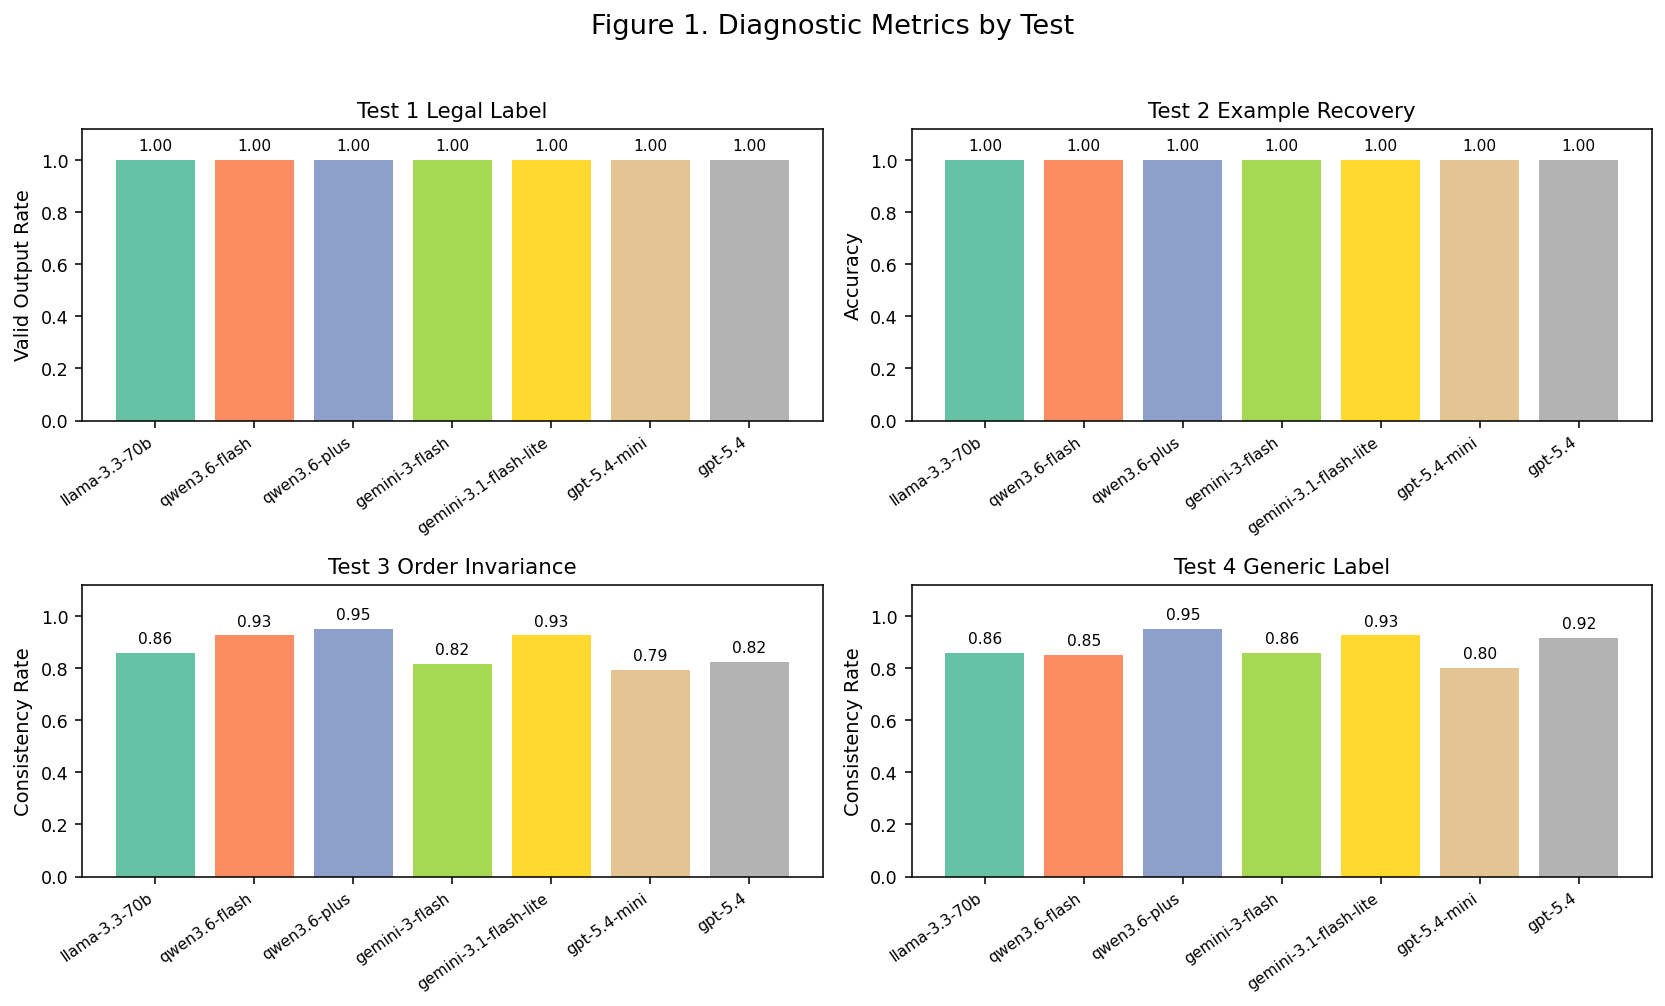

In [34]:
# Diagnostic visualizations from exported CSVs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Prefer in-memory outputs from the previous cell; otherwise read the exported CSVs.
try:
    summary_viz_df = all_summary_metrics.copy()
except NameError:
    summary_viz_df = pd.read_csv(BEHAVIORAL_RESULTS_DIR / 'all_summary_metrics.csv')

try:
    comparison_viz_df = model_comparison_master.copy()
except NameError:
    comparison_viz_df = pd.read_csv(BEHAVIORAL_RESULTS_DIR / 'model_comparison_master.csv')

FIGURE_DIR = BEHAVIORAL_RESULTS_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ORDER = comparison_viz_df['model_name'].tolist()
MODEL_COLORS = plt.cm.Set2(np.linspace(0, 1, max(len(MODEL_ORDER), 3)))[:len(MODEL_ORDER)]

plt.rcParams.update({
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 9,
})


def as_numeric(series):
    return pd.to_numeric(series, errors='coerce')


def format_model_axis(ax):
    ax.tick_params(axis='x', labelrotation=35)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')


# -----------------------------
# Figure 1. Diagnostic Metrics by Test
# -----------------------------
fig1_specs = [
    {
        'test_name': 'Legal Label Test',
        'prompt_version': 'full_codebook',
        'metric_col': 'valid_output_rate',
        'panel_title': 'Test 1 Legal Label',
        'y_label': 'Valid Output Rate',
    },
    {
        'test_name': 'Example Recovery Test',
        'prompt_version': 'full_codebook',
        'metric_col': 'accuracy',
        'panel_title': 'Test 2 Example Recovery',
        'y_label': 'Accuracy',
    },
    {
        'test_name': 'Codebook Order Invariance Test',
        'prompt_version': 'all_order_versions',
        'metric_col': 'consistency_rate',
        'panel_title': 'Test 3 Order Invariance',
        'y_label': 'Consistency Rate',
    },
    {
        'test_name': 'Generic Label Test',
        'prompt_version': 'generic_abc',
        'metric_col': 'consistency_rate',
        'panel_title': 'Test 4 Generic Label',
        'y_label': 'Consistency Rate',
    },
]

fig1_rows = []
for spec in fig1_specs:
    subset = summary_viz_df[
        (summary_viz_df['test_name'] == spec['test_name'])
        & (summary_viz_df['prompt_version'] == spec['prompt_version'])
    ].copy()
    subset['metric_value'] = as_numeric(subset[spec['metric_col']])
    subset['panel_title'] = spec['panel_title']
    subset['y_label'] = spec['y_label']
    fig1_rows.append(subset[['model_name', 'panel_title', 'y_label', 'metric_value']])
fig1_df = pd.concat(fig1_rows, ignore_index=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=False)
axes = axes.flatten()
for ax, spec in zip(axes, fig1_specs):
    plot_df = fig1_df[fig1_df['panel_title'] == spec['panel_title']].copy()
    plot_df['model_name'] = pd.Categorical(plot_df['model_name'], categories=MODEL_ORDER, ordered=True)
    plot_df = plot_df.sort_values('model_name')
    ax.bar(plot_df['model_name'].astype(str), plot_df['metric_value'], color=MODEL_COLORS)
    ax.set_title(spec['panel_title'])
    ax.set_ylabel(spec['y_label'])
    ax.set_ylim(0, 1.12)
    #ax.grid(axis='y', alpha=0.25)
    format_model_axis(ax)
    for i, value in enumerate(plot_df['metric_value']):
        if pd.notna(value):
            ax.text(i, min(value + 0.025, 1.03), f'{value:.2f}', ha='center', va='bottom', fontsize=8)
fig.suptitle('Figure 1. Diagnostic Metrics by Test', y=1.02, fontsize=14)
fig.tight_layout()
fig1_path = FIGURE_DIR / 'figure1_diagnostic_metrics_by_test.png'
fig.savefig(fig1_path, bbox_inches='tight')
plt.show()



**Test 1: Legal Label Test**:   
- gemini-2.5-flash: 0.90 -> problem with output format
- llama-3.1-8b: output almost "LOW" only, failed classification task

**Test 2: Example Recovery Test**
- llama-3.1-8b: 0.6 -> poor

**Test 3: Order Invariance Test**
- gemini-2.5-flash: 0.59 & gpt-5-mini: 0.69  -> poor
- llama-3.1-8b :0.97 -> looks high, but it's because it outputs LOW only

**Test 4: Generic Label Test**
- llama-3.1-8b: consistency 0.01, generic output becomes all HIGH
- gemini-2.5-flash: consistency 0.59, valid output rate 0.73, invalid outputs 22/80

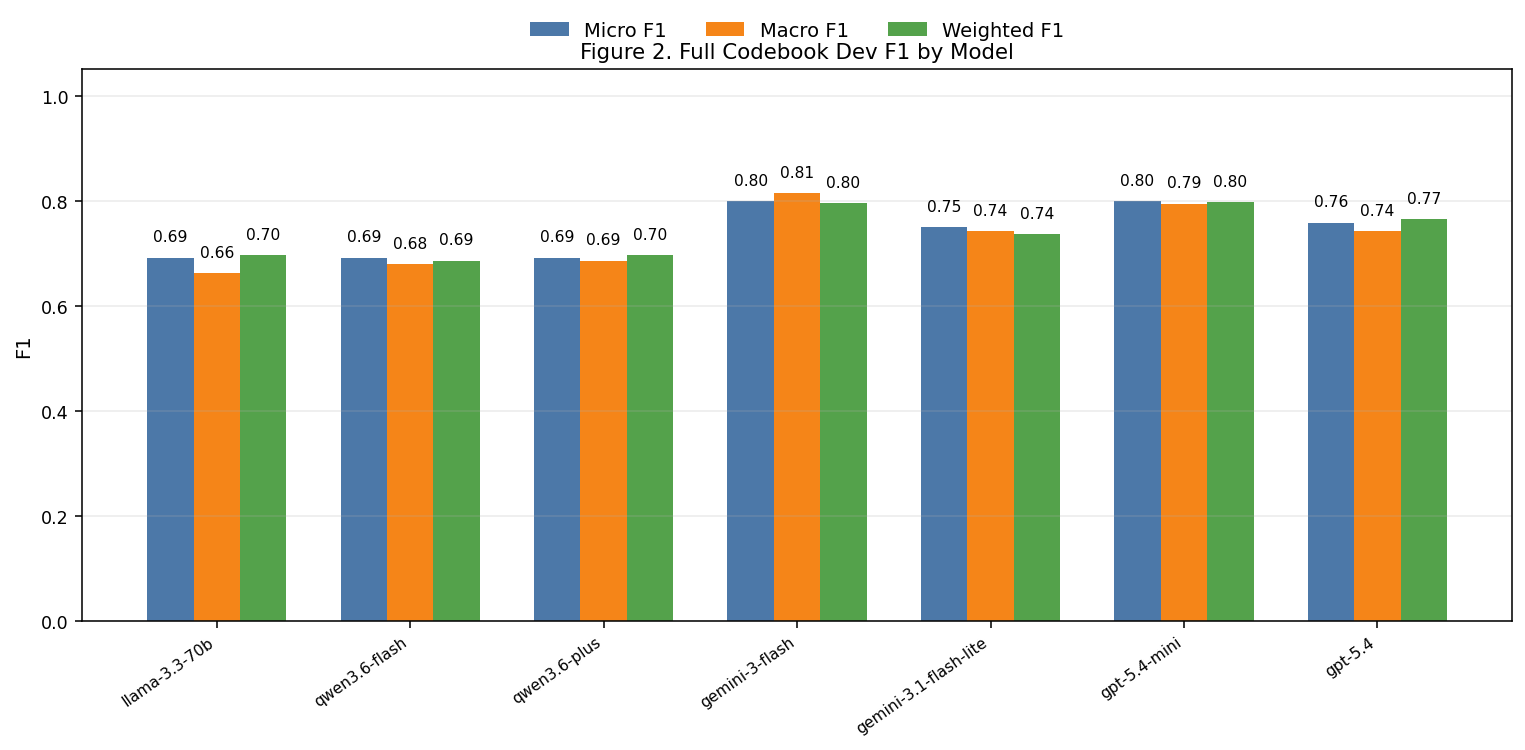

In [35]:

# -----------------------------
# Figure 2. Full Codebook Dev F1 by Model
# -----------------------------
f1_cols = {
    'full_codebook_dev_micro_f1': 'Micro F1',
    'full_codebook_dev_macro_f1': 'Macro F1',
    'full_codebook_dev_weighted_f1': 'Weighted F1',
}
fig2_df = comparison_viz_df[['model_name'] + list(f1_cols)].copy()
for col in f1_cols:
    fig2_df[col] = as_numeric(fig2_df[col])
fig2_long = fig2_df.melt(
    id_vars='model_name',
    value_vars=list(f1_cols),
    var_name='metric',
    value_name='f1',
)
fig2_long['metric'] = fig2_long['metric'].map(f1_cols)
fig2_long['model_name'] = pd.Categorical(fig2_long['model_name'], categories=MODEL_ORDER, ordered=True)
fig2_long = fig2_long.sort_values(['model_name', 'metric'])

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(MODEL_ORDER))
width = 0.24
metric_order = ['Micro F1', 'Macro F1', 'Weighted F1']
metric_colors = ['#4C78A8', '#F58518', '#54A24B']
for offset, metric, color in zip([-width, 0, width], metric_order, metric_colors):
    values = []
    for model in MODEL_ORDER:
        match = fig2_long[(fig2_long['model_name'] == model) & (fig2_long['metric'] == metric)]
        values.append(match['f1'].iloc[0] if not match.empty else np.nan)
    bars = ax.bar(x + offset, values, width=width, label=metric, color=color)
    for bar, value in zip(bars, values):
        if pd.notna(value):
            ax.text(bar.get_x() + bar.get_width() / 2, min(value + 0.025, 1.03), f'{value:.2f}', ha='center', va='bottom', fontsize=8)
ax.set_title('Figure 2. Full Codebook Dev F1 by Model')
ax.set_ylabel('F1')
ax.set_xticks(x)
ax.set_xticklabels(MODEL_ORDER, rotation=35, ha='right')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.25)
ax.legend(frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(0.5, 1.12))
fig.tight_layout()
fig2_path = FIGURE_DIR / 'figure2_full_codebook_dev_f1_by_model.png'
fig.savefig(fig2_path, bbox_inches='tight')
plt.show()


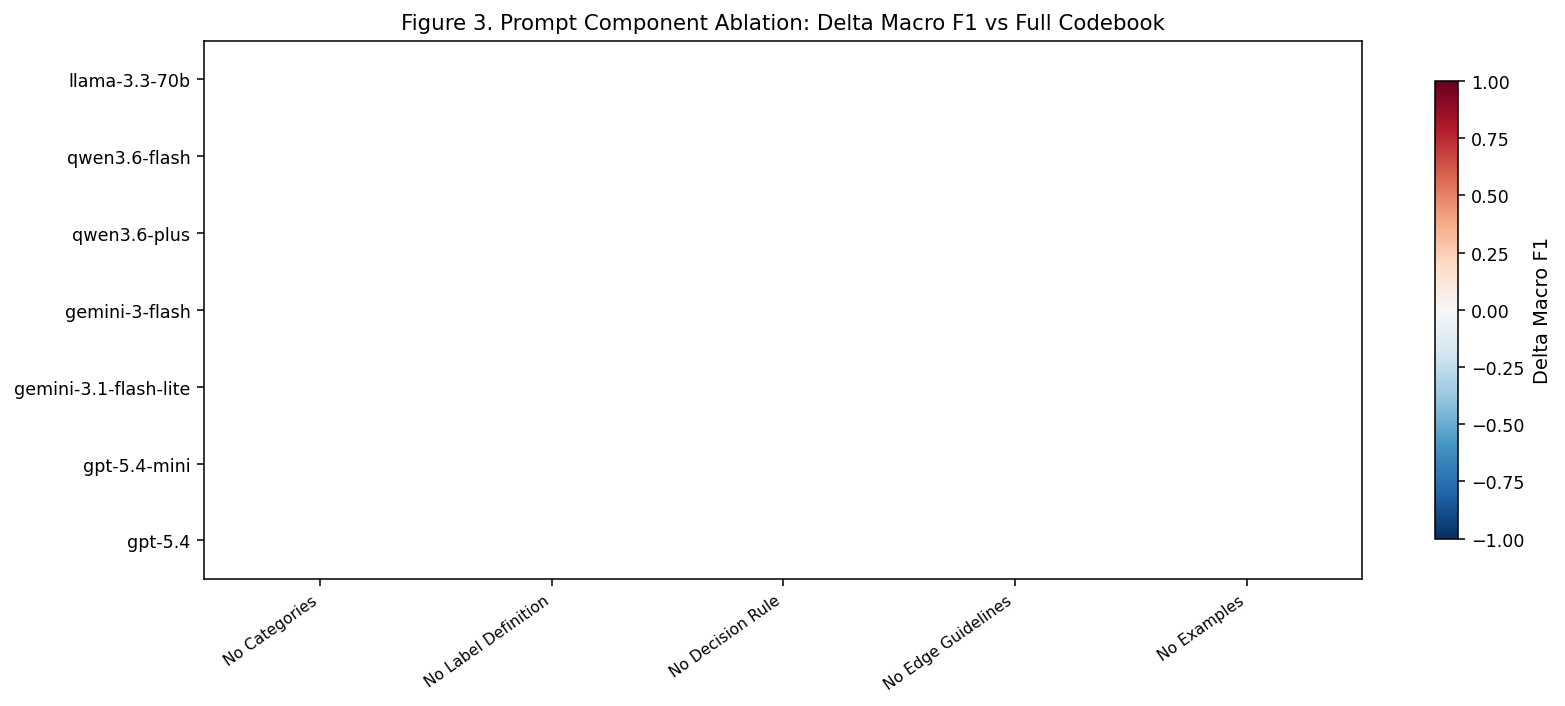

In [36]:
# -----------------------------
# Figure 3. Prompt Component Ablation Heatmap
# -----------------------------
delta_cols = {
    'no_categories_delta_macro_f1': 'No Categories',
    'no_label_definition_delta_macro_f1': 'No Label Definition',
    'no_decision_rule_delta_macro_f1': 'No Decision Rule',
    'no_edge_guidelines_delta_macro_f1': 'No Edge Guidelines',
    'no_examples_delta_macro_f1': 'No Examples',
}
fig3_df = comparison_viz_df[['model_name'] + list(delta_cols)].copy()
for col in delta_cols:
    fig3_df[col] = as_numeric(fig3_df[col])
fig3_df = fig3_df.set_index('model_name').rename(columns=delta_cols).reindex(MODEL_ORDER)
heatmap_values = fig3_df.to_numpy(dtype=float)
max_abs = np.nanmax(np.abs(heatmap_values)) if np.isfinite(heatmap_values).any() else 1.0
if max_abs == 0 or np.isnan(max_abs):
    max_abs = 1.0

fig, ax = plt.subplots(figsize=(12, max(3.8, 0.45 * len(MODEL_ORDER) + 2)))
im = ax.imshow(heatmap_values, cmap='RdBu_r', vmin=-max_abs, vmax=max_abs, aspect='auto')
ax.set_title('Figure 3. Prompt Component Ablation: Delta Macro F1 vs Full Codebook')
ax.set_xticks(np.arange(len(fig3_df.columns)))
ax.set_xticklabels(fig3_df.columns, rotation=35, ha='right')
ax.set_yticks(np.arange(len(fig3_df.index)))
ax.set_yticklabels(fig3_df.index)

for i in range(heatmap_values.shape[0]):
    for j in range(heatmap_values.shape[1]):
        value = heatmap_values[i, j]
        label = '' if np.isnan(value) else f'{value:+.3f}'
        ax.text(j, i, label, ha='center', va='center', color='black', fontsize=9)

cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label('Delta Macro F1')
fig.tight_layout()
fig3_path = FIGURE_DIR / 'figure3_prompt_component_ablation_heatmap.png'
fig.savefig(fig3_path, bbox_inches='tight')
plt.show()

In [37]:
all_summary_metrics[all_summary_metrics['model_name']=='llama-3.1-8b']

,run_id,model_name,model_version,test_name,prompt_version,split,n_items,valid_output_rate,accuracy,micro_f1,macro_f1,weighted_f1,high_f1,low_f1,none_f1,agreement_with_full,consistency_rate,label_distribution,invalid_output_count,notes


# Final Zero-Shot Test Set Evaluation

Run the selected models once on the held-out test set with the finalized full codebook prompt, then compare model-level metrics.


In [38]:
# Final zero-shot evaluation on the held-out test set
# This cell writes separate final-test outputs and does not overwrite pre-zero-shot diagnostic CSVs.

SELECTED_TEST_MODELS = {
    'llama-3.3-70b':    ('groq',   'llama-3.3-70b-versatile'),
    "qwen3.6-flash": ("qwen", "qwen3.6-flash"),
    "qwen3.6-plus": ("qwen", "qwen3.6-plus"),
    "gemini-3-flash": ("google", "gemini-3-flash-preview"),
    "gemini-3.1-flash-lite": ("google", "gemini-3.1-flash-lite"),
    "gpt-5.4-mini": ("openai", "gpt-5.4-mini"),
    'gpt-5.4':           ('openai', 'gpt-5.4')

}

MAX_NEW_TOKENS = 30

FINAL_TEST_RESULTS_DIR = RESULTS_DIR / "final_test_results"
FINAL_TEST_PREDICTIONS_DIR = FINAL_TEST_RESULTS_DIR / "predictions"
FINAL_TEST_FIGURE_DIR = FINAL_TEST_RESULTS_DIR / "figures"
FINAL_TEST_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FINAL_TEST_PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
FINAL_TEST_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

FINAL_TEST_RUN_ID = f"final_zero_shot_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}_{uuid.uuid4().hex[:8]}"
FINAL_TEST_TIMESTAMP = datetime.now(timezone.utc).isoformat()
FINAL_TEST_NAME = "Final Zero-Shot Test"
FINAL_PROMPT_VERSION = "full_codebook"

# Use the complete held-out test split, independent of PILOT_MODE.
test_items = dataframe_to_items(
    df[df['split'].astype(str).str.lower() == 'test'].reset_index(drop=True),
    split_name='test',
    prefix='test',
)
print(f"FINAL_TEST_RUN_ID: {FINAL_TEST_RUN_ID}")
print(f"Test items: {len(test_items)}")

FINAL_TEST_RUN_ID: final_zero_shot_20260810T031617Z_c433f3dd
Test items: 240


In [39]:
def final_cache_path(model_key: str, prompt_version: str = FINAL_PROMPT_VERSION) -> Path:
    safe_model = re.sub(r"[^A-Za-z0-9_.-]+", "_", model_key)
    safe_prompt = re.sub(r"[^A-Za-z0-9_.-]+", "_", prompt_version)
    return FINAL_TEST_PREDICTIONS_DIR / f"{safe_model}_final_zero_shot_{safe_prompt}_test.jsonl"


def save_jsonl(path: Path, records: List[dict]) -> None:
    with jsonlines.open(path, 'w') as writer:
        for record in records:
            writer.write(record)
    print(f"  Saved {len(records)} records to {path.name}")


def load_jsonl(path: Path) -> Optional[List[dict]]:
    if not path.exists():
        return None
    with jsonlines.open(path) as reader:
        return list(reader)


def run_final_test_predictions(model_key: str) -> List[dict]:
    """Run or load final test-set predictions for one model."""
    path = final_cache_path(model_key)
    cached = load_jsonl(path)
    model_name, model_version = model_metadata(model_key)
    if cached is not None:
        print(f"  [cache hit] {model_key}/final_zero_shot_test: {len(cached)} records")
        records = cached
    else:
        print(f"  [computing] {model_key}/final_zero_shot_test")
        prompts = [build_full_prompt(item['paragraph']) for item in test_items]
        raw_outputs = batch_call_llm(
            model_key,
            prompts,
            max_tokens=MAX_NEW_TOKENS,
        )
        parsed = parse_answers(raw_outputs, CANONICAL_LABELS)
        records = []
        for item, raw, parsed_label in zip(test_items, raw_outputs, parsed):
            gold = item.get('gold_label', '')
            records.append({
                'run_id': FINAL_TEST_RUN_ID,
                'timestamp': FINAL_TEST_TIMESTAMP,
                'model_name': model_name,
                'model_version': model_version,
                'temperature': TEMPERATURE,
                'test_name': FINAL_TEST_NAME,
                'prompt_version': FINAL_PROMPT_VERSION,
                'split': 'test',
                'item_id': item['item_id'],
                'title': item.get('title', ''),
                'paragraph': item['paragraph'],
                'gold_label': gold,
                'expected_label': '',
                'model_output_raw': raw,
                'parsed_label': parsed_label or '',
                'valid_output': parsed_label in CANONICAL_LABELS,
                'correct_against_expected': '',
                'correct_against_gold': (parsed_label == gold) if gold else '',
                'matches_baseline': '',
                'notes': '',
            })
        save_jsonl(path, records)

    # Refresh run metadata for this export while preserving cached raw outputs.
    for row in records:
        row['run_id'] = FINAL_TEST_RUN_ID
        row['timestamp'] = FINAL_TEST_TIMESTAMP
        row['model_name'] = model_name
        row['model_version'] = model_version
        row['temperature'] = TEMPERATURE
        row['test_name'] = FINAL_TEST_NAME
        row['prompt_version'] = FINAL_PROMPT_VERSION
        row['split'] = 'test'
    return records


def confusion_matrix_from_records(records: List[dict], model_key: str) -> pd.DataFrame:
    rows = []
    for gold in CANONICAL_LABELS:
        subset = [r for r in records if r.get('gold_label') == gold]
        row = {'model_name': model_key, 'gold_label': gold}
        for pred in CANONICAL_LABELS + ['INVALID']:
            row[f'pred_{pred.lower()}'] = sum((r.get('parsed_label') or 'INVALID') == pred for r in subset)
        rows.append(row)
    return pd.DataFrame(rows)


# Temporarily use only the selected final-test models with the existing call_llm/model_metadata helpers.
_original_models = MODELS.copy()
MODELS = SELECTED_TEST_MODELS.copy()

all_final_item_rows = []
final_summary_rows = []
final_confusion_rows = []

try:
    for model_key in MODELS:
        print(f"\n=== Final test: {model_key} ===")
        records = run_final_test_predictions(model_key)
        all_final_item_rows.extend(records)

        summary = summary_row(
            model_key=model_key,
            test_name=FINAL_TEST_NAME,
            prompt_version=FINAL_PROMPT_VERSION,
            records=records,
            split='test',
            target_field='gold_label',
        )
        final_summary_rows.append(summary)
        final_confusion_rows.append(confusion_matrix_from_records(records, model_key))
finally:
    # Restore diagnostic MODELS in case later cells rely on it.
    MODELS = _original_models

final_test_item_level_predictions = pd.DataFrame(all_final_item_rows, columns=ITEM_LEVEL_COLUMNS).fillna('')
final_test_summary_metrics = pd.DataFrame(final_summary_rows, columns=SUMMARY_METRIC_COLUMNS).fillna('')
final_test_confusion_matrices = pd.concat(final_confusion_rows, ignore_index=True).fillna('')

final_test_model_comparison = final_test_summary_metrics[[
    'model_name', 'model_version', 'n_items', 'valid_output_rate', 'accuracy',
    'micro_f1', 'macro_f1', 'weighted_f1', 'high_f1', 'low_f1', 'none_f1',
    'label_distribution', 'invalid_output_count'
]].copy()
final_test_model_comparison = final_test_model_comparison.sort_values(
    ['macro_f1', 'weighted_f1', 'accuracy'], ascending=False
).reset_index(drop=True)

item_path = FINAL_TEST_RESULTS_DIR / 'final_test_item_level_predictions.csv'
summary_path = FINAL_TEST_RESULTS_DIR / 'final_test_summary_metrics.csv'
comparison_path = FINAL_TEST_RESULTS_DIR / 'final_test_model_comparison.csv'
confusion_path = FINAL_TEST_RESULTS_DIR / 'final_test_confusion_matrices.csv'

final_test_item_level_predictions.to_csv(item_path, index=False)
final_test_summary_metrics.to_csv(summary_path, index=False)
final_test_model_comparison.to_csv(comparison_path, index=False)
final_test_confusion_matrices.to_csv(confusion_path, index=False)

print("\nSaved final test outputs:")
print(f"- {item_path}")
print(f"- {summary_path}")
print(f"- {comparison_path}")
print(f"- {confusion_path}")


=== Final test: llama-3.3-70b ===
  [cache hit] llama-3.3-70b/final_zero_shot_test: 240 records

=== Final test: qwen3.6-flash ===
  [cache hit] qwen3.6-flash/final_zero_shot_test: 240 records

=== Final test: qwen3.6-plus ===
  [cache hit] qwen3.6-plus/final_zero_shot_test: 240 records

=== Final test: gemini-3-flash ===
  [cache hit] gemini-3-flash/final_zero_shot_test: 240 records

=== Final test: gemini-3.1-flash-lite ===
  [cache hit] gemini-3.1-flash-lite/final_zero_shot_test: 240 records

=== Final test: gpt-5.4-mini ===
  [cache hit] gpt-5.4-mini/final_zero_shot_test: 240 records

=== Final test: gpt-5.4 ===
  [cache hit] gpt-5.4/final_zero_shot_test: 240 records

Saved final test outputs:
- /content/drive/MyDrive/Interiority_26Spring/Data/results/final_test_results/final_test_item_level_predictions.csv
- /content/drive/MyDrive/Interiority_26Spring/Data/results/final_test_results/final_test_summary_metrics.csv
- /content/drive/MyDrive/Interiority_26Spring/Data/results/final_te

In [40]:
print("\nFinal test model comparison:")
display(final_test_model_comparison)


Final test model comparison:


,model_name,model_version,n_items,valid_output_rate,accuracy,micro_f1,macro_f1,weighted_f1,high_f1,low_f1,none_f1,label_distribution,invalid_output_count
0,gemini-3-flash,gemini-3-flash-preview,240,1.0,0.762500,0.762500,0.739762,0.761439,0.840580,0.720812,0.657895,"{""HIGH"": 103, ""LOW"": 104, ""NONE"": 33}",0
1,gpt-5.4-mini,gpt-5.4-mini,240,1.0,0.704167,0.704167,0.698981,0.707081,0.762887,0.659898,0.674157,"{""HIGH"": 90, ""LOW"": 104, ""NONE"": 46}",0
2,gemini-3.1-flash-lite,gemini-3.1-flash-lite,240,1.0,0.691667,0.691667,0.673646,0.693216,0.813725,0.596685,0.610526,"{""HIGH"": 100, ""LOW"": 88, ""NONE"": 52}",0
3,gpt-5.4,gpt-5.4,240,1.0,0.670833,0.670833,0.673048,0.675949,0.707317,0.645161,0.666667,"{""HIGH"": 60, ""LOW"": 124, ""NONE"": 56}",0
4,llama-3.3-70b,llama-3.3-70b-versatile,240,1.0,0.637500,0.637500,0.622126,0.646855,0.731429,0.607477,0.527473,"{""HIGH"": 71, ""LOW"": 121, ""NONE"": 48}",0
5,qwen3.6-flash,qwen3.6-flash,240,1.0,0.620833,0.620833,0.612396,0.621539,0.730964,0.511628,0.594595,"{""HIGH"": 93, ""LOW"": 79, ""NONE"": 68}",0
6,qwen3.6-plus,qwen3.6-plus,240,1.0,0.583333,0.583333,0.584675,0.588577,0.620253,0.560000,0.573770,"{""HIGH"": 54, ""LOW"": 107, ""NONE"": 79}",0


In [41]:
print("\nConfusion matrices:")
display(final_test_confusion_matrices)


Confusion matrices:


,model_name,gold_label,pred_high,pred_low,pred_none,pred_invalid
0,llama-3.3-70b,HIGH,64,38,2,0
1,llama-3.3-70b,LOW,6,65,22,0
2,llama-3.3-70b,NONE,1,18,24,0
3,qwen3.6-flash,HIGH,72,28,4,0
4,qwen3.6-flash,LOW,18,44,31,0
5,qwen3.6-flash,NONE,3,7,33,0
6,qwen3.6-plus,HIGH,49,43,12,0
7,qwen3.6-plus,LOW,5,56,32,0
8,qwen3.6-plus,NONE,0,8,35,0
9,gemini-3-flash,HIGH,87,17,0,0


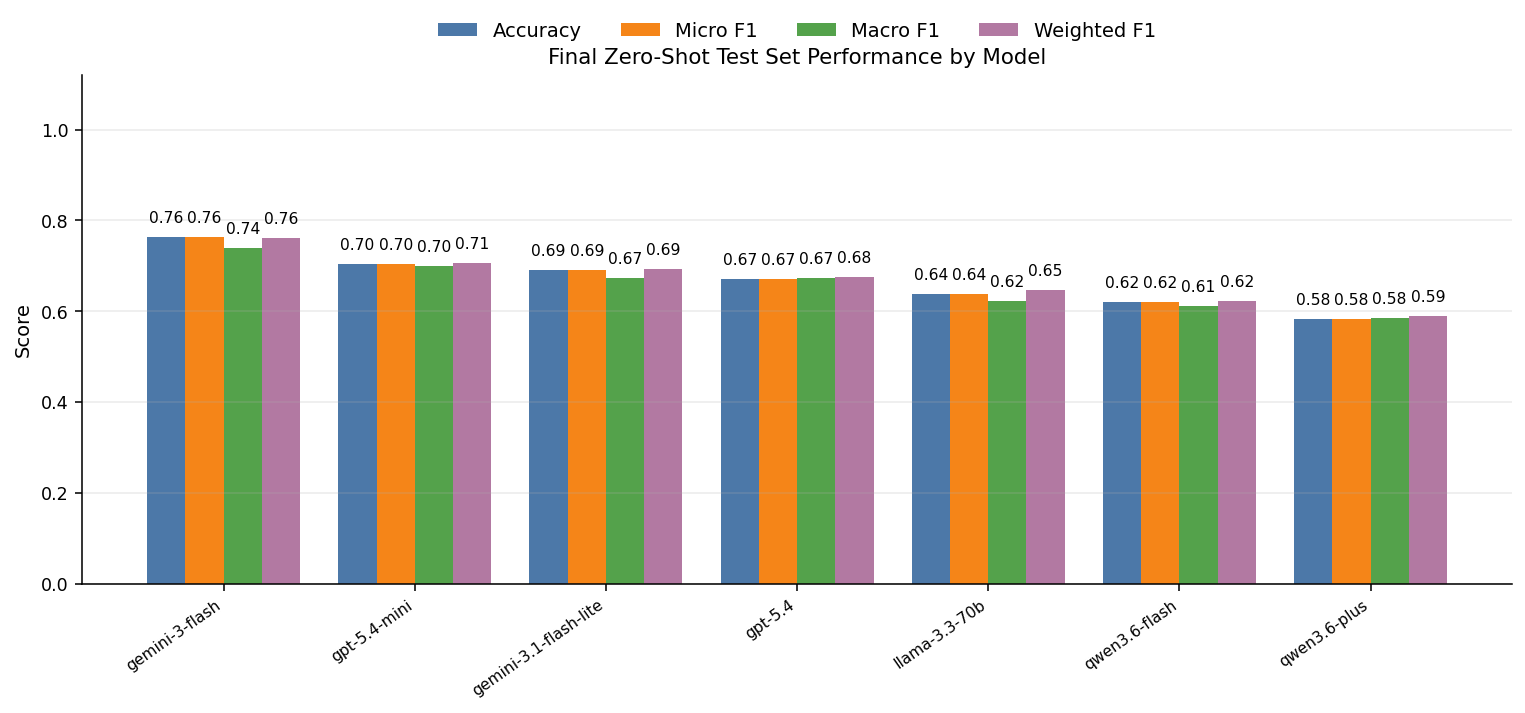

Saved figure: /content/drive/MyDrive/Interiority_26Spring/Data/results/final_test_results/figures/final_test_model_performance.png


In [42]:
# Final test-set comparison figure

try:
    final_compare_viz = final_test_model_comparison.copy()
except NameError:
    final_compare_viz = pd.read_csv(FINAL_TEST_RESULTS_DIR / 'final_test_model_comparison.csv')

metric_cols = {
    'accuracy': 'Accuracy',
    'micro_f1': 'Micro F1',
    'macro_f1': 'Macro F1',
    'weighted_f1': 'Weighted F1',
}
for col in metric_cols:
    final_compare_viz[col] = pd.to_numeric(final_compare_viz[col], errors='coerce')

model_order = final_compare_viz['model_name'].tolist()
x = np.arange(len(model_order))
width = 0.2
colors = ['#4C78A8', '#F58518', '#54A24B', '#B279A2']

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=140)
for offset, (col, label), color in zip(
    [-1.5 * width, -0.5 * width, 0.5 * width, 1.5 * width],
    metric_cols.items(),
    colors,
):
    values = final_compare_viz[col].to_numpy(dtype=float)
    bars = ax.bar(x + offset, values, width=width, label=label, color=color)
    for bar, value in zip(bars, values):
        if pd.notna(value):
            ax.text(bar.get_x() + bar.get_width() / 2, min(value + 0.025, 1.08), f'{value:.2f}', ha='center', va='bottom', fontsize=8)

ax.set_title('Final Zero-Shot Test Set Performance by Model')
ax.set_ylabel('Score')
ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=35, ha='right')
ax.set_ylim(0, 1.12)
ax.grid(axis='y', alpha=0.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False, ncols=4, loc='upper center', bbox_to_anchor=(0.5, 1.14))
fig.tight_layout(rect=[0, 0, 1, 0.96])

final_fig_path = FINAL_TEST_FIGURE_DIR / 'final_test_model_performance.png'
fig.savefig(final_fig_path, bbox_inches='tight', dpi=300)
plt.show()

print(f'Saved figure: {final_fig_path}')


In [43]:
# Bootstrap report for final test-set results

try:
    bootstrap_items = final_test_item_level_predictions.copy()
except NameError:
    bootstrap_items = pd.read_csv(FINAL_TEST_RESULTS_DIR / 'final_test_item_level_predictions.csv', keep_default_na=False)

BOOTSTRAP_N = 1000
BOOTSTRAP_CONFIDENCE = 0.95
BOOTSTRAP_SEED = SEED
BOOTSTRAP_LABELS = CANONICAL_LABELS


def _as_label_array(values):
    return np.array([str(v).strip().upper() if str(v).strip().upper() in BOOTSTRAP_LABELS else 'INVALID' for v in values])


def _f1_for_label(labels, preds, target_label):
    labels = _as_label_array(labels)
    preds = _as_label_array(preds)
    tp = np.sum((labels == target_label) & (preds == target_label))
    fp = np.sum((labels != target_label) & (preds == target_label))
    fn = np.sum((labels == target_label) & (preds != target_label))
    denom = (2 * tp) + fp + fn
    return float((2 * tp) / denom) if denom else 0.0


def metric_accuracy(labels, preds):
    labels = _as_label_array(labels)
    preds = _as_label_array(preds)
    return float(np.mean(labels == preds)) if len(labels) else np.nan


def metric_micro_f1(labels, preds):
    labels = _as_label_array(labels)
    preds = _as_label_array(preds)
    total_tp = total_fp = total_fn = 0
    for label in BOOTSTRAP_LABELS:
        total_tp += np.sum((labels == label) & (preds == label))
        total_fp += np.sum((labels != label) & (preds == label))
        total_fn += np.sum((labels == label) & (preds != label))
    denom = (2 * total_tp) + total_fp + total_fn
    return float((2 * total_tp) / denom) if denom else 0.0


def metric_macro_f1(labels, preds):
    return float(np.mean([_f1_for_label(labels, preds, label) for label in BOOTSTRAP_LABELS]))


def metric_weighted_f1(labels, preds):
    labels_arr = _as_label_array(labels)
    supports = np.array([np.sum(labels_arr == label) for label in BOOTSTRAP_LABELS], dtype=float)
    f1s = np.array([_f1_for_label(labels, preds, label) for label in BOOTSTRAP_LABELS], dtype=float)
    total_support = supports.sum()
    return float(np.sum(f1s * supports) / total_support) if total_support else 0.0


def make_label_f1_metric(target_label):
    return lambda labels, preds: _f1_for_label(labels, preds, target_label)


def bootstrap_ci(labels, preds, metric_fn, n_bootstrap=1000, confidence=0.95, seed=42):
    """Bootstrap point estimate and percentile confidence interval.

    labels and preds are resampled as paired observations so each prediction
    remains matched to its original gold label.
    """
    labels = np.array(labels)
    preds = np.array(preds)
    n = len(labels)
    if n == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    boot_scores = []
    for _ in range(n_bootstrap):
        sample_idx = rng.integers(0, n, size=n)
        boot_scores.append(metric_fn(labels[sample_idx], preds[sample_idx]))

    alpha = (1 - confidence) / 2
    lower = np.percentile(boot_scores, 100 * alpha)
    upper = np.percentile(boot_scores, 100 * (1 - alpha))
    point = metric_fn(labels, preds)
    return float(point), float(lower), float(upper)


BOOTSTRAP_METRICS = {
    'accuracy': metric_accuracy,
    'micro_f1': metric_micro_f1,
    'macro_f1': metric_macro_f1,
    'weighted_f1': metric_weighted_f1,
    'high_f1': make_label_f1_metric('HIGH'),
    'low_f1': make_label_f1_metric('LOW'),
    'none_f1': make_label_f1_metric('NONE'),
}

bootstrap_rows = []
for model_name, model_df in bootstrap_items.groupby('model_name', sort=False):
    labels = model_df['gold_label'].to_numpy()
    preds = model_df['parsed_label'].to_numpy()
    n_items = len(model_df)
    invalid_output_count = int(np.sum(_as_label_array(preds) == 'INVALID'))

    for metric_name, metric_fn in BOOTSTRAP_METRICS.items():
        point, lower, upper = bootstrap_ci(
            labels,
            preds,
            metric_fn,
            n_bootstrap=BOOTSTRAP_N,
            confidence=BOOTSTRAP_CONFIDENCE,
            seed=BOOTSTRAP_SEED,
        )
        bootstrap_rows.append({
            'model_name': model_name,
            'metric': metric_name,
            'point': point,
            'ci_lower': lower,
            'ci_upper': upper,
            'ci_width': upper - lower,
            'n_items': n_items,
            'invalid_output_count': invalid_output_count,
            'n_bootstrap': BOOTSTRAP_N,
            'confidence': BOOTSTRAP_CONFIDENCE,
        })

final_test_bootstrap_report = pd.DataFrame(bootstrap_rows)
bootstrap_path = FINAL_TEST_RESULTS_DIR / 'final_test_bootstrap_report.csv'
final_test_bootstrap_report.to_csv(bootstrap_path, index=False)

print(f"Saved bootstrap report to: {bootstrap_path}")

display(
    final_test_bootstrap_report.assign(
        estimate_ci=final_test_bootstrap_report.apply(
            lambda r: f"{r['point']:.3f} [{r['ci_lower']:.3f}, {r['ci_upper']:.3f}]",
            axis=1,
        )
    ).pivot(index='model_name', columns='metric', values='estimate_ci')
)


Saved bootstrap report to: /content/drive/MyDrive/Interiority_26Spring/Data/results/final_test_results/final_test_bootstrap_report.csv


metric,accuracy,high_f1,low_f1,macro_f1,micro_f1,none_f1,weighted_f1
model_name,,,,,,,
gemini-3-flash,"0.762 [0.713, 0.817]","0.841 [0.785, 0.890]","0.721 [0.655, 0.790]","0.740 [0.678, 0.801]","0.762 [0.713, 0.817]","0.658 [0.520, 0.778]","0.761 [0.709, 0.815]"
gemini-3.1-flash-lite,"0.692 [0.633, 0.746]","0.814 [0.752, 0.865]","0.597 [0.508, 0.677]","0.674 [0.610, 0.731]","0.692 [0.633, 0.746]","0.611 [0.487, 0.717]","0.693 [0.636, 0.748]"
gpt-5.4,"0.671 [0.608, 0.725]","0.707 [0.620, 0.779]","0.645 [0.567, 0.711]","0.673 [0.608, 0.726]","0.671 [0.608, 0.725]","0.667 [0.549, 0.755]","0.676 [0.616, 0.728]"
gpt-5.4-mini,"0.704 [0.642, 0.758]","0.763 [0.689, 0.824]","0.660 [0.577, 0.732]","0.699 [0.630, 0.752]","0.704 [0.642, 0.758]","0.674 [0.545, 0.767]","0.707 [0.646, 0.760]"
llama-3.3-70b,"0.637 [0.575, 0.700]","0.731 [0.654, 0.802]","0.607 [0.527, 0.681]","0.622 [0.554, 0.688]","0.637 [0.575, 0.700]","0.527 [0.388, 0.639]","0.647 [0.585, 0.709]"
qwen3.6-flash,"0.621 [0.554, 0.679]","0.731 [0.652, 0.795]","0.512 [0.415, 0.596]","0.612 [0.547, 0.668]","0.621 [0.554, 0.679]","0.595 [0.473, 0.696]","0.622 [0.558, 0.682]"
qwen3.6-plus,"0.583 [0.521, 0.642]","0.620 [0.528, 0.706]","0.560 [0.470, 0.634]","0.585 [0.517, 0.640]","0.583 [0.521, 0.642]","0.574 [0.456, 0.662]","0.589 [0.527, 0.646]"


In [68]:
def bootstrap_ci(
    labels,
    preds,
    metric_fn,
    groups,
    n_bootstrap=1000,
    confidence=0.95,
    seed=42,
):
    """Book-level cluster bootstrap percentile CI.

    Books are resampled with replacement. All passages belonging to a
    sampled book are retained together. Predictions remain paired with
    their gold labels.
    """
    labels = np.asarray(labels)
    preds = np.asarray(preds)
    groups = np.asarray(groups)

    if not (len(labels) == len(preds) == len(groups)):
        raise ValueError("labels, preds, and groups must have the same length.")

    if len(labels) == 0:
        return np.nan, np.nan, np.nan

    unique_groups = np.unique(groups)
    n_groups = len(unique_groups)

    # Passage indices belonging to each book
    group_indices = {
        g: np.flatnonzero(groups == g)
        for g in unique_groups
    }

    rng = np.random.default_rng(seed)
    boot_scores = np.empty(n_bootstrap)

    for b in range(n_bootstrap):
        # Sample books with replacement
        sampled_groups = rng.choice(
            unique_groups,
            size=n_groups,
            replace=True,
        )

        # A book sampled twice contributes all of its passages twice
        sample_idx = np.concatenate([
            group_indices[g] for g in sampled_groups
        ])

        boot_scores[b] = metric_fn(
            labels[sample_idx],
            preds[sample_idx],
        )

    alpha = (1 - confidence) / 2
    lower, upper = np.percentile(
        boot_scores,
        [100 * alpha, 100 * (1 - alpha)],
    )

    # Point estimate remains the metric on the original full test set
    point = metric_fn(labels, preds)

    return float(point), float(lower), float(upper)

bootstrap_rows = []
for model_name, model_df in bootstrap_items.groupby("model_name", sort=False):
    labels = model_df["gold_label"].to_numpy()
    preds = model_df["parsed_label"].to_numpy()
    groups = model_df["title"].to_numpy()

    n_items = len(model_df)
    n_books = model_df["title"].nunique()

    invalid_output_count = int(
        np.sum(_as_label_array(preds) == "INVALID")
    )

    for metric_name, metric_fn in BOOTSTRAP_METRICS.items():
        point, lower, upper = bootstrap_ci(
            labels,
            preds,
            metric_fn,
            groups=groups,
            n_bootstrap=BOOTSTRAP_N,
            confidence=BOOTSTRAP_CONFIDENCE,
            seed=BOOTSTRAP_SEED,
        )

        bootstrap_rows.append({
            "model_name": model_name,
            "metric": metric_name,
            "point": point,
            "ci_lower": lower,
            "ci_upper": upper,
            "ci_width": upper - lower,
            "n_items": n_items,
            "n_books": n_books,
            "invalid_output_count": invalid_output_count,
            "n_bootstrap": BOOTSTRAP_N,
            "confidence": BOOTSTRAP_CONFIDENCE,
        })

In [71]:
# Build a completely fresh report from the current bootstrap run
fresh_report = pd.DataFrame.from_records(bootstrap_rows)

print("Rows in fresh report:", len(fresh_report))
print("Models:", fresh_report["model_name"].nunique())
print("Metrics:", len(BOOTSTRAP_METRICS))

expected_rows = (
    fresh_report["model_name"].nunique()
    * len(BOOTSTRAP_METRICS)
)
print("Expected rows:", expected_rows)

# Check duplicates BEFORE assigning to final_test_bootstrap_report
duplicate_counts = (
    fresh_report
    .groupby(["model_name", "metric"], dropna=False)
    .size()
    .reset_index(name="n")
    .query("n > 1")
)

display(duplicate_counts)

assert duplicate_counts.empty, "Duplicates were generated inside bootstrap_rows."

# Explicitly overwrite the old dataframe
final_test_bootstrap_report = fresh_report.copy()

Rows in fresh report: 49
Models: 7
Metrics: 7
Expected rows: 49


,model_name,metric,n


In [73]:
final_test_bootstrap_report = pd.DataFrame(bootstrap_rows)
#bootstrap_path = FINAL_TEST_RESULTS_DIR / 'final_test_bootstrap_report.csv'
#final_test_bootstrap_report.to_csv(bootstrap_path, index=False)

#print(f"Saved bootstrap report to: {bootstrap_path}")

display(
    final_test_bootstrap_report.assign(
        estimate_ci=final_test_bootstrap_report.apply(
            lambda r: f"{r['point']:.3f} [{r['ci_lower']:.3f}, {r['ci_upper']:.3f}]",
            axis=1,
        )
    ).pivot(index='model_name', columns='metric', values='estimate_ci')
)


metric,accuracy,high_f1,low_f1,macro_f1,micro_f1,none_f1,weighted_f1
model_name,,,,,,,
gemini-3-flash,"0.762 [0.742, 0.783]","0.841 [0.809, 0.867]","0.721 [0.649, 0.780]","0.740 [0.712, 0.761]","0.762 [0.742, 0.783]","0.658 [0.625, 0.686]","0.761 [0.741, 0.782]"
gemini-3.1-flash-lite,"0.692 [0.642, 0.733]","0.814 [0.773, 0.842]","0.597 [0.503, 0.685]","0.674 [0.601, 0.732]","0.692 [0.642, 0.733]","0.611 [0.507, 0.673]","0.693 [0.647, 0.732]"
gpt-5.4,"0.671 [0.592, 0.738]","0.707 [0.625, 0.770]","0.645 [0.537, 0.736]","0.673 [0.592, 0.737]","0.671 [0.592, 0.738]","0.667 [0.588, 0.723]","0.676 [0.604, 0.739]"
gpt-5.4-mini,"0.704 [0.654, 0.758]","0.763 [0.707, 0.812]","0.660 [0.545, 0.749]","0.699 [0.640, 0.756]","0.704 [0.654, 0.758]","0.674 [0.600, 0.747]","0.707 [0.660, 0.760]"
llama-3.3-70b,"0.637 [0.588, 0.679]","0.731 [0.677, 0.771]","0.607 [0.500, 0.694]","0.622 [0.564, 0.663]","0.637 [0.588, 0.679]","0.527 [0.448, 0.591]","0.647 [0.601, 0.682]"
qwen3.6-flash,"0.621 [0.554, 0.671]","0.731 [0.663, 0.795]","0.512 [0.387, 0.610]","0.612 [0.527, 0.670]","0.621 [0.554, 0.671]","0.595 [0.486, 0.682]","0.622 [0.549, 0.674]"
qwen3.6-plus,"0.583 [0.475, 0.671]","0.620 [0.458, 0.724]","0.560 [0.448, 0.661]","0.585 [0.467, 0.674]","0.583 [0.475, 0.671]","0.574 [0.435, 0.678]","0.589 [0.483, 0.674]"


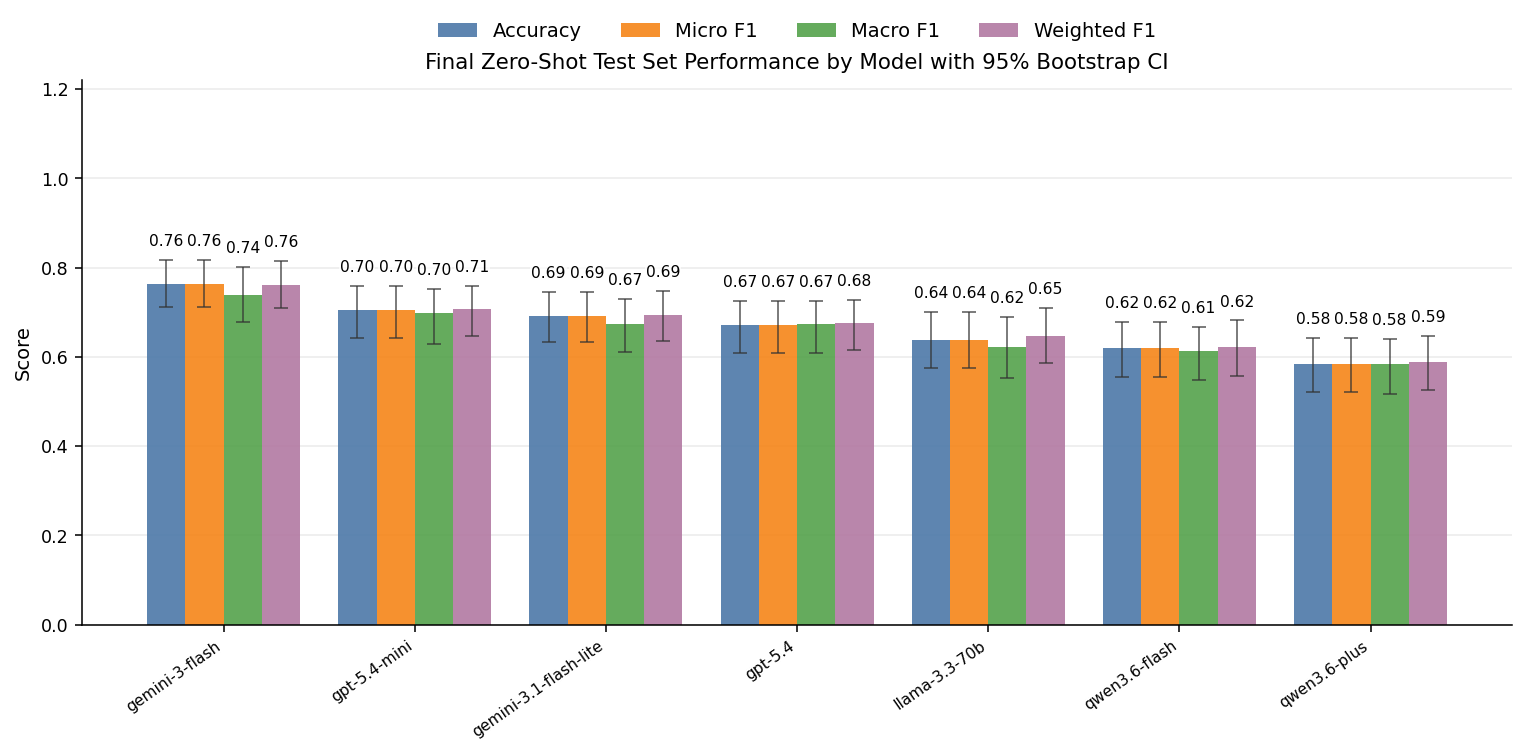

Saved figure: /content/drive/MyDrive/Interiority_26Spring/Data/results/final_test_results/figures/final_test_model_performance_bootstrap_ci_front_errorbars.png


In [45]:
# Final test-set comparison figure with bootstrap confidence intervals drawn in front of bars
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    bootstrap_viz_df_front = final_test_bootstrap_report.copy()
except NameError:
    bootstrap_viz_df_front = pd.read_csv(FINAL_TEST_RESULTS_DIR / 'final_test_bootstrap_report.csv')

plot_metrics = {
    'accuracy': 'Accuracy',
    'micro_f1': 'Micro F1',
    'macro_f1': 'Macro F1',
    'weighted_f1': 'Weighted F1',
}

plot_df = bootstrap_viz_df_front[bootstrap_viz_df_front['metric'].isin(plot_metrics)].copy()
for col in ['point', 'ci_lower', 'ci_upper']:
    plot_df[col] = pd.to_numeric(plot_df[col], errors='coerce')
plot_df['metric_label'] = plot_df['metric'].map(plot_metrics)

try:
    model_order = final_test_model_comparison['model_name'].tolist()
except NameError:
    model_order = plot_df.groupby('model_name', sort=False)['point'].mean().sort_values(ascending=False).index.tolist()

x = np.arange(len(model_order))
width = 0.2
metric_order = list(plot_metrics.values())
metric_colors = ['#4C78A8', '#F58518', '#54A24B', '#B279A2']
metric_offsets = [-1.5 * width, -0.5 * width, 0.5 * width, 1.5 * width]

fig, ax = plt.subplots(figsize=(11, 5.8), dpi=140)
for offset, metric_label, color in zip(metric_offsets, metric_order, metric_colors):
    points = []
    lower_err = []
    upper_err = []
    for model in model_order:
        match = plot_df[(plot_df['model_name'] == model) & (plot_df['metric_label'] == metric_label)]
        if match.empty:
            points.append(np.nan)
            lower_err.append(np.nan)
            upper_err.append(np.nan)
            continue
        row = match.iloc[0]
        point = row['point']
        points.append(point)
        lower_err.append(max(point - row['ci_lower'], 0.0))
        upper_err.append(max(row['ci_upper'] - point, 0.0))

    xpos = x + offset
    ax.bar(
        xpos,
        points,
        width=width,
        label=metric_label,
        color=color,
        alpha=0.9,
        zorder=2,
    )

    # Draw CI on top of bars so both upper and lower halves remain visible.
    ax.errorbar(
        xpos,
        points,
        yerr=np.array([lower_err, upper_err]),
        fmt='none',
        ecolor='#333333',
        elinewidth=1.0,
        capsize=3.5,
        capthick=1.0,
        alpha=0.65,
        zorder=5,
    )

    for x_i, value, upper in zip(xpos, points, upper_err):
        if pd.notna(value):
            label_y = min(value + upper + 0.025, 1.14)
            ax.text(
                x_i,
                label_y,
                f'{value:.2f}',
                ha='center',
                va='bottom',
                fontsize=8,
                zorder=6,
                bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.72, 'pad': 0.5},
            )

ax.set_title('Final Zero-Shot Test Set Performance by Model with 95% Bootstrap CI')
ax.set_ylabel('Score')
ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=35, ha='right')
ax.set_ylim(0, 1.22)
ax.grid(axis='y', alpha=0.25, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(frameon=False, ncols=4, loc='upper center', bbox_to_anchor=(0.5, 1.14))
fig.tight_layout(rect=[0, 0, 1, 0.96])

bootstrap_fig_front_path = FINAL_TEST_FIGURE_DIR / 'final_test_model_performance_bootstrap_ci_front_errorbars.png'
fig.savefig(bootstrap_fig_front_path, bbox_inches='tight', dpi=300)
plt.show()

print(f'Saved figure: {bootstrap_fig_front_path}')


# Final Test Per-Book F1 Summary


In [46]:
# Per-book final test F1 summary

try:
    per_book_items = final_test_item_level_predictions.copy()
except NameError:
    per_book_items = pd.read_csv(FINAL_TEST_RESULTS_DIR / 'final_test_item_level_predictions.csv', keep_default_na=False)

per_book_rows = []
for (model_name, title), group in per_book_items.groupby(['model_name', 'title'], sort=False):
    records = group.to_dict('records')
    metrics = classification_metrics(records, 'gold_label')
    invalid_count = int((group['parsed_label'].fillna('').astype(str).str.strip() == '').sum())
    n_items = len(group)
    valid_rate = (n_items - invalid_count) / n_items if n_items else np.nan
    label_counts = group['parsed_label'].replace('', 'INVALID').fillna('INVALID').value_counts().to_dict()

    row = {
        'model_name': model_name,
        'title': title,
        'n_items': n_items,
        'valid_output_rate': valid_rate,
        'invalid_output_count': invalid_count,
        'label_distribution': json.dumps(label_counts, sort_keys=True),
    }
    row.update(metrics)
    per_book_rows.append(row)

final_test_per_book_f1_summary = pd.DataFrame(per_book_rows)

# Keep a readable order: books by overall item count, models by final comparison order when available.
try:
    model_order = final_test_model_comparison['model_name'].tolist()
except NameError:
    model_order = final_test_per_book_f1_summary['model_name'].drop_duplicates().tolist()
book_order = (
    final_test_per_book_f1_summary.groupby('title', sort=False)['n_items']
    .max()
    .sort_values(ascending=False)
    .index
    .tolist()
)
final_test_per_book_f1_summary['model_name'] = pd.Categorical(
    final_test_per_book_f1_summary['model_name'], categories=model_order, ordered=True
)
final_test_per_book_f1_summary['title'] = pd.Categorical(
    final_test_per_book_f1_summary['title'], categories=book_order, ordered=True
)
final_test_per_book_f1_summary = final_test_per_book_f1_summary.sort_values(['title', 'model_name']).reset_index(drop=True)

per_book_path = FINAL_TEST_RESULTS_DIR / 'final_test_per_book_f1_summary.csv'
final_test_per_book_f1_summary.to_csv(per_book_path, index=False)

print(f'Saved per-book F1 summary to: {per_book_path}')
display(final_test_per_book_f1_summary)


Saved per-book F1 summary to: /content/drive/MyDrive/Interiority_26Spring/Data/results/final_test_results/final_test_per_book_f1_summary.csv


,model_name,title,n_items,valid_output_rate,invalid_output_count,label_distribution,accuracy,micro_f1,macro_f1,weighted_f1,high_f1,low_f1,none_f1
0,gemini-3-flash,A farewell to arms,40,1.0,0,"{""HIGH"": 6, ""LOW"": 26, ""NONE"": 8}",0.800,0.800,0.795996,0.793556,0.923077,0.833333,0.631579
1,gpt-5.4-mini,A farewell to arms,40,1.0,0,"{""HIGH"": 10, ""LOW"": 19, ""NONE"": 11}",0.675,0.675,0.666145,0.678551,0.588235,0.682927,0.727273
2,gemini-3.1-flash-lite,A farewell to arms,40,1.0,0,"{""HIGH"": 9, ""LOW"": 17, ""NONE"": 14}",0.775,0.775,0.788077,0.774202,0.875000,0.769231,0.720000
3,gpt-5.4,A farewell to arms,40,1.0,0,"{""HIGH"": 4, ""LOW"": 22, ""NONE"": 14}",0.750,0.750,0.740000,0.750273,0.727273,0.772727,0.720000
4,llama-3.3-70b,A farewell to arms,40,1.0,0,"{""HIGH"": 5, ""LOW"": 25, ""NONE"": 10}",0.675,0.675,0.653833,0.671682,0.666667,0.723404,0.571429
5,qwen3.6-flash,A farewell to arms,40,1.0,0,"{""HIGH"": 6, ""LOW"": 16, ""NONE"": 18}",0.700,0.700,0.686072,0.692629,0.615385,0.684211,0.758621
6,qwen3.6-plus,A farewell to arms,40,1.0,0,"{""HIGH"": 4, ""LOW"": 19, ""NONE"": 17}",0.725,0.725,0.724422,0.726140,0.727273,0.731707,0.714286
7,gemini-3-flash,Dubliners,40,1.0,0,"{""HIGH"": 13, ""LOW"": 19, ""NONE"": 8}",0.750,0.750,0.747619,0.747143,0.800000,0.742857,0.700000
8,gpt-5.4-mini,Dubliners,40,1.0,0,"{""HIGH"": 11, ""LOW"": 19, ""NONE"": 10}",0.750,0.750,0.749595,0.748922,0.869565,0.742857,0.636364
9,gemini-3.1-flash-lite,Dubliners,40,1.0,0,"{""HIGH"": 14, ""LOW"": 14, ""NONE"": 12}",0.725,0.725,0.726496,0.720513,0.846154,0.666667,0.666667


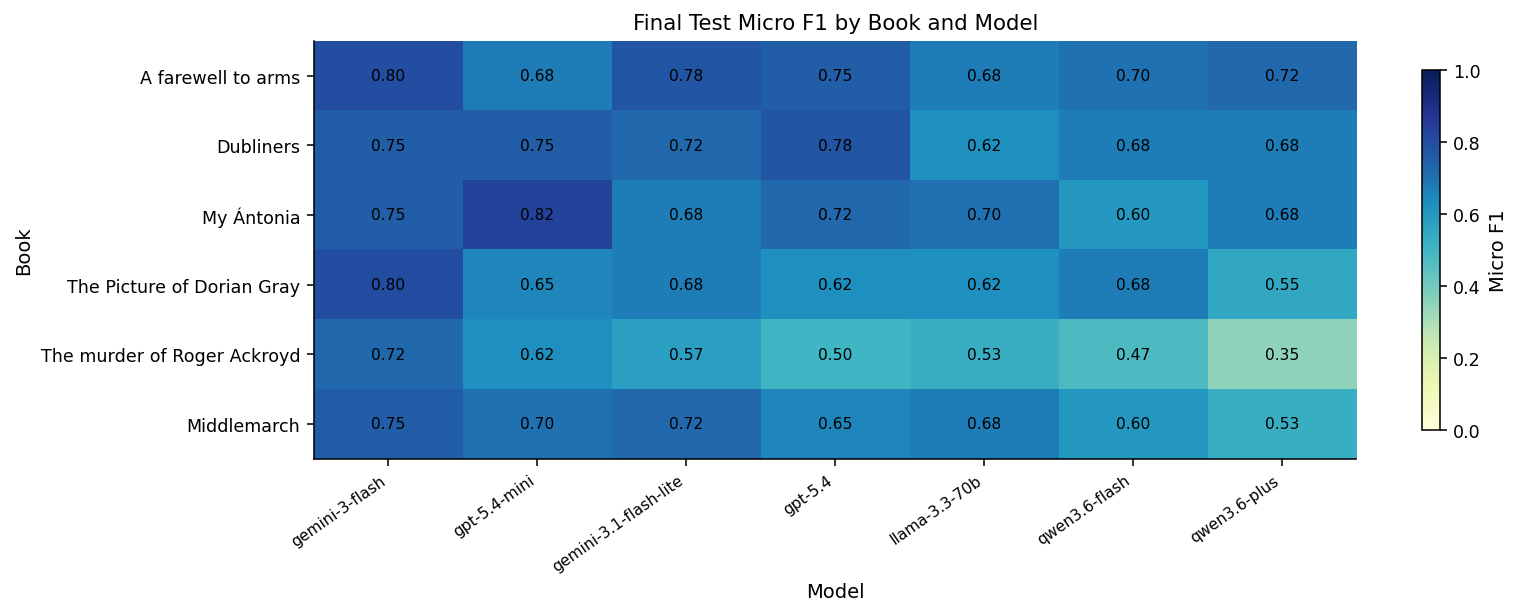

Saved figure: /content/drive/MyDrive/Interiority_26Spring/Data/results/final_test_results/figures/final_test_per_book_micro_f1_heatmap.png


In [47]:
# Per-book final test F1 heatmap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    per_book_viz_df = final_test_per_book_f1_summary.copy()
except NameError:
    per_book_viz_df = pd.read_csv(FINAL_TEST_RESULTS_DIR / 'final_test_per_book_f1_summary.csv')

metric_to_plot = 'micro_f1'
heatmap_df = per_book_viz_df.pivot(index='title', columns='model_name', values=metric_to_plot)
heatmap_df = heatmap_df.apply(pd.to_numeric, errors='coerce')

fig_height = max(4.5, 0.45 * len(heatmap_df.index) + 1.8)
fig_width = max(8.5, 1.25 * len(heatmap_df.columns) + 3)
fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=140)

values = heatmap_df.to_numpy(dtype=float)
im = ax.imshow(values, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')

ax.set_title('Final Test Micro F1 by Book and Model')
ax.set_xlabel('Model')
ax.set_ylabel('Book')
ax.set_xticks(np.arange(len(heatmap_df.columns)))
ax.set_xticklabels(heatmap_df.columns, rotation=35, ha='right')
ax.set_yticks(np.arange(len(heatmap_df.index)))
ax.set_yticklabels(heatmap_df.index)

for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        value = values[i, j]
        if np.isnan(value):
            label = ''
        else:
            label = f'{value:.2f}'
        ax.text(j, i, label, ha='center', va='center', fontsize=8, color='black')

cbar = fig.colorbar(im, ax=ax, shrink=0.86)
cbar.set_label('Micro F1')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()

per_book_fig_path = FINAL_TEST_FIGURE_DIR / 'final_test_per_book_micro_f1_heatmap.png'
fig.savefig(per_book_fig_path, bbox_inches='tight', dpi=300)
plt.show()

print(f'Saved figure: {per_book_fig_path}')
